# x50 データの回帰（ラグなし、目的変数の変換・説明変数・CV を選べる、残差解析つき）

- **作成者**: ImoZukushi
- **作成日**: 2026-10-31
- **目的**: `008_pipeline_x50_regression.ipynb` をもとに、時系列としてではなく通常の回帰タスクとして、全種類
  （`Y_cat` = Y1〜Y10）を1つのモデルで学習する。パラメータで条件を切り替えて試し、CV の結果と残差解析を確認する。
- **008 との違い**
  - 目的変数のラグ・移動平均は作らない。
  - 目的変数の変換を「行わない（既定）・対数・正規化」から選べる（`TARGET_TRANSFORM`）。
  - 使う説明変数を、CSV を読み込むときに指定できる（`FEATURE_COLS`）。
  - 説明変数のスケーリングを「行わない（既定）・正規化・ロバストスケーリング」から選べる（`FEATURE_SCALING`）。
    べき変換は行わない。
  - `irregular_flg` が True の行は、学習にも予測にも使わない。
  - CV を GroupKFold・時系列から選べる（`CV_METHOD`）。
  - 誤差曲線・誤差分布などの残差解析を行う。
  - テストの正解ファイルは使わない（作らないため）。テストの MAE は計算せず、評価は CV で行う。
- **入力**（ダミー。`scripts/generate_dummy_x50.py` で作成）
  - 学習: `data/synthetic/x50/dummy_x50_train.csv`（2022-01-01〜2024-12-31）
  - テスト: `data/synthetic/x50/dummy_x50_test.csv`（2025-01-01〜2025-12-31、目的変数の値なし）
- **出力**
  - 前処理済みの CSV: `data/processed/x50_regression/`
  - `outputs/experiments/x50_regression_009_{モデル名}/{実行日時}/`（CV スコア・予測・図・SHAP・残差解析）
  - テスト予測: `outputs/predictions/x50_regression_009_{モデル名}_{実行日時}.csv`
    （列 `ID`, `date`, `Y_cat`, `pred`。テストデータの全行。`irregular_flg` が True の行の `pred` は0）
  - MLflow（`mlruns/`）、ログファイル `outputs/logs/`
- **用語**: 正規化は、`(x - 最小値) / (最大値 - 最小値)` で 0〜1 にそろえる変換（min-max）を指す。

## リークを防ぐための決まり

| 段階 | 決まり | どこで確かめるか |
|---|---|---|
| 行の選択 | `irregular_flg` が True の行は、読み込みの直後に除く。前処理の fit・学習・予測のどれにも入らない | 4. 前処理のリークの確認 / 予測のリークの確認 |
| 日付の前処理 | 経過日数の基準日は学習データだけで決める | 4. 前処理のリークの確認 |
| 説明変数のスケーリング | `modeling` の Pipeline に入れ、CV の各 fold の学習側だけで fit する | `make_config` |
| 系列ID | 整数化（`PandasOrdinalEncoder`）も、各 fold の学習側だけで fit する | `make_config` |
| 目的変数の変換 | 正規化の最小値・最大値は、種類ごとに、各 fold の学習側だけで求める。予測は元の尺度に戻してから評価する | `train_cv` |
| 特徴量 | 系列ID・日付の特徴量・説明変数だけ。目的変数・日付・グループの列が入っていないこと | 6. 学習用データとリークの確認（`prepare`） |
| CV（GroupKFold） | グループは年月。同じ月の行は学習と検証に分かれない。検証の月より後の月も学習に使う | `prepare` |
| CV（時系列） | `CUTOFFS` の日付で区切る。学習は境目より前だけ | `prepare` |
| 予測 | 各行の予測は、その行の特徴量だけから行う | 予測のリークの確認 |
| 欠損 | 欠損は埋めない。目的変数が欠損の行は学習・評価から除く。説明変数の欠損はモデルに任せる | `model_frames` |

**注意:** GroupKFold の CV は、未来の月も学習に使うため、学習データより後の期間の予測より楽観的になりやすい。
時間の流れに沿って確かめたいときは `CV_METHOD = "timeseries"` を使う。

In [1]:
import datetime as dt
import gc
import hashlib
import logging
import shutil
import sys
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# pyproject.toml を目印にリポジトリルートを探し、src/ をimportパスに追加する
# （scripts/ の関数は import せず、このノートブック内で定義する）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# ipywidgets が無い環境で tqdm が出す警告（進捗バーの表示だけの問題）は出さない
warnings.filterwarnings("ignore", message="IProgress not found")

# src/ 配下のモジュール（上でパスを追加した後にimportする必要がある）
from evaluation.residuals import (  # noqa: E402
    ResidualCorrelogramDisplay,
    plot_residuals_by_group,
    residual_summary,
)
from feature_engineering.datetime_features import (  # noqa: E402
    CyclicalFeaturesEncoder,
    DatetimeFeaturesExtractor,
    ElapsedTimeTransformer,
)
from modeling.config import ExperimentConfig  # noqa: E402
from modeling.cv import folds_to_ids  # noqa: E402
from modeling.dataset import Dataset  # noqa: E402
from modeling.evaluation import EVALUATION_DIR, save_evaluation_outputs  # noqa: E402
from modeling.experiment import (  # noqa: E402
    ExperimentResult,
    make_output_dir,
    prepare_dataset,
    save_cv_outputs,
)
from modeling.explain import compute_oof_shap, save_shap_outputs  # noqa: E402
from modeling.metrics import get_metric  # noqa: E402
from modeling.models import get_model_spec  # noqa: E402
from modeling.tasks import Task, predict  # noqa: E402
from modeling.tracking import MLflowTracker, NullTracker, Tracker  # noqa: E402
from modeling.trainer import CVResult, fit_pipeline  # noqa: E402
from util.csv_io import detect_encoding  # noqa: E402
from util.paths import data_dir, ensure_parent_dir, get_repo_root, outputs_dir  # noqa: E402
from util.plotting import add_caption, ensure_japanese_font  # noqa: E402

# pandas の表示で列を省略しすぎないようにする
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

## パラメータ

papermill で実行するときは `-p 名前 値` で上書きできる（このセルに `parameters` タグを付けている）。
リストや真偽値は `-y` で YAML として渡す。

```bash
uv run papermill notebook/009_regression_x50.ipynb out.ipynb --cwd notebook \
    -y "{TARGET_TRANSFORM: log, FEATURE_SCALING: robust, CV_METHOD: timeseries, FEATURE_COLS: [X1, X2, X11]}"
```

| パラメータ | 選べる値 | 既定 |
|---|---|---|
| `TARGET_TRANSFORM` | `None`（行わない）、`"log"`（対数）、`"normalize"`（種類ごとの正規化） | `None` |
| `FEATURE_COLS` | 使う説明変数のリスト。`None` なら全部 | `None` |
| `FEATURE_SCALING` | `None`（行わない）、`"normalize"`（正規化）、`"robust"`（ロバストスケーリング） | `None` |
| `FEATURE_SCALING_COLS` | スケーリングする説明変数のリスト。`None` なら使う説明変数の全部 | `None` |
| `CV_METHOD` | `"group"`（GroupKFold）、`"timeseries"`（日付で区切る時系列CV） | `"group"` |

In [2]:
# --- 入力・出力（data/ からの相対パス） ---
RAW_TRAIN_PATH = "synthetic/x50/dummy_x50_train.csv"  # 学習データ
RAW_TEST_PATH = "synthetic/x50/dummy_x50_test.csv"  # テストデータ（目的変数の値なし）
FEATURES_DIR = "processed/x50_regression"  # 前処理済みの CSV の出力先

# --- 列 ---
DATE_COL = "date"  # 日付
CAT_COL = "Y_cat"  # 目的変数の種類（Y1〜Y10）
TARGET_COL = "Y"  # 目的変数の値
IRREGULAR_COL = "irregular_flg"  # True の行は学習にも予測にも使わない
TARGET_CATS = None  # 使う種類（None なら学習データの全種類）
# 使う説明変数（None なら全部。例: ["X1", "X2", "X11"]）。CSV を読み込むときに、この列だけを読む
FEATURE_COLS = None

# --- 前処理 ---
TARGET_TRANSFORM = None  # None（行わない）/ "log"（対数）/ "normalize"（種類ごとの正規化）
TARGET_LOG_OFFSET = 0.0  # 対数の変換で log(y + offset) にする値
FEATURE_SCALING = None  # None（行わない）/ "normalize"（正規化）/ "robust"（ロバストスケーリング）
FEATURE_SCALING_COLS = None  # スケーリングする説明変数（None なら使う説明変数の全部）
DATE_COMPONENTS = ["year", "month", "day", "weekday", "week"]  # 日付から取り出す成分

# --- 学習 ---
MODEL = "lightgbm"  # "lightgbm" または "xgboost"
DETAIL_TARGET = "Y1"  # 詳しい図を表示する種類
CV_METHOD = "group"  # "group"（GroupKFold）または "timeseries"（日付で区切る時系列CV）
N_SPLITS = 5  # GroupKFold の分割数（グループ = 年月）
CUTOFFS = ["2023-07-01", "2024-01-01"]  # 時系列CVの検証期間の開始日
TEST_PREDICTION = "refit_full"  # "refit_full"（全学習データで学習し直す）または "fold_mean"
LEARNING_CURVE = False  # 学習データの量を変えた学習曲線も作るか（学習し直すので時間がかかる）
USE_TRACKING = True  # MLflow に記録するか
OUTPUT_ROOT = None  # 出力のルート（None なら outputs/experiments）
# 画面に出すログのレベル（ファイル outputs/logs/ には INFO 以上を残す）
LOG_LEVEL = "WARNING"

## 関数の定義

このノートブックは `scripts/` を import せず、使う関数をここで定義する。ログ・図の部品は 004、要約は 008 と同じ関数。
008 では `modeling.experiment.run_experiment` を使うが、目的変数の変換を fold ごとに行うため、ここでは同じ流れの
`train_cv`・`run_training` を定義する。

### 定数と結果の入れ物

In [3]:
MODELS = ("lightgbm", "xgboost")
TARGET_TRANSFORMS = (None, "log", "normalize")
GROUP_COL = "year_month"  # GroupKFold のグループ（年月。例: 2022-01）
ID_COL = "ID"  # テスト予測の CSV の連番の列
PRED_COL = "pred"  # 予測値の列
ACTUAL_COL = "actual"  # 正解の列
MLFLOW_EXPERIMENT = "x50_forecast"
SCALERS = {
    "normalize": "feature_engineering.scaling.PandasMinMaxScaler",
    "robust": "feature_engineering.scaling.PandasRobustScaler",
}

logger = logging.getLogger("regression_x50")


class LeakageError(ValueError):
    """入力データにリークのおそれがある場合のエラー。"""


class TargetScaler:
    """目的変数の変換（行わない・対数・種類ごとの正規化）と、元の尺度に戻す処理。

    正規化の最小値・最大値は `fit` に渡した行（CV の学習側）だけから求める。

    Args:
        kind: `None` / `"log"` / `"normalize"`。
        offset: 対数の変換で `log(y + offset)` にする値。

    Raises:
        ValueError: 未対応の変換の場合。
    """

    def __init__(self, kind: str | None, offset: float = 0.0) -> None:
        if kind not in TARGET_TRANSFORMS:
            raise ValueError(f"TARGET_TRANSFORM は {TARGET_TRANSFORMS} から選んでください: {kind}")
        self.kind = kind
        self.offset = offset

    def fit(self, y: np.ndarray, categories: np.ndarray) -> "TargetScaler":
        """変換に必要な値を学習する。

        Raises:
            ValueError: 対数を取れない値（`y + offset <= 0`）がある場合。
        """
        if self.kind == "log" and (y + self.offset <= 0).any():
            raise ValueError(
                "対数を取れない目的変数があります。TARGET_LOG_OFFSET を指定してください"
            )
        if self.kind == "normalize":
            grouped = pd.Series(y).groupby(categories)
            self.low_ = grouped.min()
            # 値が1種類しかない種類は、0除算にならないよう幅を1にする
            self.span_ = (grouped.max() - self.low_).replace(0.0, 1.0)
        return self

    def transform(self, y: np.ndarray, categories: np.ndarray) -> np.ndarray:
        """モデルが学習する尺度に変換する。"""
        if self.kind == "log":
            return np.log(y + self.offset)
        if self.kind == "normalize":
            cats = pd.Series(categories)
            return (y - cats.map(self.low_).to_numpy()) / cats.map(self.span_).to_numpy()
        return y

    def inverse(self, z: np.ndarray, categories: np.ndarray) -> np.ndarray:
        """モデルの尺度の値を、元の尺度に戻す。"""
        if self.kind == "log":
            return np.exp(z) - self.offset
        if self.kind == "normalize":
            cats = pd.Series(categories)
            return z * cats.map(self.span_).to_numpy() + cats.map(self.low_).to_numpy()
        return z


@dataclass
class RegressionRun:
    """学習・予測の結果。

    Attributes:
        categories: 目的変数の種類の並び。
        dataset: 学習用データ一式。
        frame: 学習に使った行の表（`dataset.X` と同じ行順）。
        result: 実験の結果（CV の結果・出力先・MLflow の run ID）。
        predictions: テスト予測（long 型。列 `date`, `Y_cat`, `pred`）。
        oof: 学習期間の OOF 予測（long 型。列 `date`, `Y_cat`, `actual`, `pred`, `fold`）。
        target_scalers: `result.cv_result.models` と同じ並びの、目的変数の変換。
    """

    categories: list[str]
    dataset: Dataset
    frame: pd.DataFrame
    result: ExperimentResult
    predictions: pd.DataFrame
    oof: pd.DataFrame
    target_scalers: list[TargetScaler]

In [4]:
TRAIN_PATH = data_dir() / FEATURES_DIR / "x50_train_features.csv"
TEST_PATH = data_dir() / FEATURES_DIR / "x50_test_features.csv"

### ログ（004 と同じ）

In [5]:
def setup_logging(
    log_path: Path, level: int = logging.INFO, console_level: int | None = None
) -> Path:
    """画面とファイルの両方にログを出す設定をする（同じ設定を2回呼んでも重複しない）。

    Args:
        log_path: ログファイルのパス（UTF-8）。
        level: ログの出力レベル（ファイル）。
        console_level: 画面に出すログのレベル（Noneなら `level` と同じ）。画面への出力量を減らしたい
            とき（小さいインスタンスの Jupyter など）は `logging.WARNING` にする。ファイルには
            `level` 以上のログが残る。

    Returns:
        ログファイルのパス。
    """
    ensure_parent_dir(log_path)
    console_level = level if console_level is None else console_level
    root = logging.getLogger()
    root.setLevel(min(level, console_level))
    for handler in list(root.handlers):
        if getattr(handler, "_x50", False):
            root.removeHandler(handler)
            handler.close()
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(name)s: %(message)s")
    file_handler = logging.FileHandler(log_path, encoding="utf-8")
    file_handler.setLevel(level)
    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(console_level)
    handlers: list[logging.Handler] = [file_handler, console_handler]
    for handler in handlers:
        handler.setFormatter(formatter)
        handler._x50 = True  # type: ignore[attr-defined]
        root.addHandler(handler)
    # ライブラリの警告もログに残す（細かい情報ログは出さない）
    logging.captureWarnings(True)
    for name in ("matplotlib", "PIL", "shap", "urllib3", "alembic", "mlflow"):
        logging.getLogger(name).setLevel(logging.WARNING)
    return log_path


def shown(path: Path) -> str:
    """ログ・画面に出すパス（リポジトリ内ならルートからの相対パス。個人のフォルダ名を残さない）。"""
    resolved = Path(path).resolve()
    root = get_repo_root()
    return resolved.relative_to(root).as_posix() if resolved.is_relative_to(root) else str(path)


def file_digest(path: Path) -> str:
    """ファイルの SHA-256（先頭12文字）。どのデータで学習したかをログに残すために使う。"""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]


def make_tracker(enabled: bool) -> Tracker:
    """MLflow に記録する（`enabled=False` なら何も記録しない）。"""
    return MLflowTracker(MLFLOW_EXPERIMENT) if enabled else NullTracker()

### 読み込みとモデルに渡す表

In [6]:
def read_columns(path: Path, feature_cols: list[str] | None, with_target: bool) -> pd.DataFrame:
    """CSV から、使う列だけを読み込む（メモリを節約し、使う説明変数をここで決める）。

    Args:
        path: CSV のパス。
        feature_cols: 使う説明変数（None なら全部）。
        with_target: 目的変数の列も読むか。

    Raises:
        ValueError: 必要な列が CSV に無い場合。
    """
    encoding = detect_encoding(path)
    encoding = "utf-8-sig" if encoding == "utf-8" else encoding
    header = list(pd.read_csv(path, nrows=0, encoding=encoding).columns)
    meta = [DATE_COL, CAT_COL, IRREGULAR_COL, *([TARGET_COL] if with_target else [])]
    excluded = {DATE_COL, CAT_COL, IRREGULAR_COL, TARGET_COL}
    features = [c for c in header if c not in excluded] if feature_cols is None else feature_cols
    missing = [c for c in [*meta, *features] if c not in header]
    if missing:
        raise ValueError(f"{path.name} に列がありません: {missing}")
    frame = pd.read_csv(path, usecols=[*meta, *features], encoding=encoding)
    frame[DATE_COL] = pd.to_datetime(frame[DATE_COL], format="%Y-%m-%d")
    if frame[IRREGULAR_COL].dtype != bool:
        raise ValueError(f"{IRREGULAR_COL} は bool 型にしてください: {frame[IRREGULAR_COL].dtype}")
    return frame[[*meta, *features]]


def drop_irregular(frame: pd.DataFrame) -> pd.DataFrame:
    """`irregular_flg` が True の行を除き、フラグの列も外す（学習にも予測にも使わない）。"""
    return (
        frame.loc[~frame[IRREGULAR_COL]]
        .drop(columns=IRREGULAR_COL)
        .sort_values(DATE_COL, kind="stable")
        .reset_index(drop=True)
    )


def model_frames(
    train: pd.DataFrame, test: pd.DataFrame, exog_cols: list[str]
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """`prepare_dataset` に渡す学習・テストの表を作る。

    学習の表は「日付・系列ID・年月（グループ）・日付の特徴量・説明変数・目的変数」。
    目的変数が欠損の行は学習できないため除く。ラグ・移動平均は作らない。

    Returns:
        (学習の表, テストの表（目的変数なし）)。
    """
    columns = [DATE_COL, CAT_COL, *exog_cols]
    used = train[train[TARGET_COL].notna()]
    frame = used[columns].assign(
        **{GROUP_COL: used[DATE_COL].dt.strftime("%Y-%m"), TARGET_COL: used[TARGET_COL]}
    )
    return frame.reset_index(drop=True), test[columns].reset_index(drop=True)

### 実験設定

In [7]:
def make_config(
    model: str,
    feature_cols: list[str],
    cv_method: str = "group",
    n_splits: int = 5,
    cutoffs: list[str] | None = None,
    test_prediction: str = "refit_full",
    feature_scaling: str | None = None,
    scaling_cols: list[str] | None = None,
    learning_curve: bool = False,
) -> ExperimentConfig:
    """通常の回帰の実験設定を作る（`ExperimentConfig` で検証する）。

    説明変数のスケーリングは Pipeline に入れるので、CV の各 fold の学習側だけで fit される。

    Args:
        model: モデル名（`lightgbm` / `xgboost`）。
        feature_cols: 使う説明変数。
        cv_method: `group`（GroupKFold）/ `timeseries`（日付で区切る時系列CV）。
        n_splits: GroupKFold の分割数。
        cutoffs: 時系列CVの検証期間の開始日。
        test_prediction: テスト予測の作り方（`refit_full` / `fold_mean`）。
        feature_scaling: `None` / `normalize` / `robust`。
        scaling_cols: スケーリングする説明変数（None なら `feature_cols` の全部）。
        learning_curve: 学習曲線を作るか。

    Raises:
        ValueError: 未対応の値や、使わない説明変数をスケーリングの対象に指定した場合。
    """
    if model not in MODELS:
        raise ValueError(f"モデルは {MODELS} から選んでください: {model}")
    if feature_scaling is not None and feature_scaling not in SCALERS:
        raise ValueError(f"FEATURE_SCALING は None か {list(SCALERS)} です: {feature_scaling}")
    features = [
        {
            "class": "feature_engineering.categorical.PandasOrdinalEncoder",
            "params": {"variables": [CAT_COL]},
        }
    ]
    if feature_scaling is not None:
        columns = feature_cols if scaling_cols is None else scaling_cols
        unknown = sorted(set(columns) - set(feature_cols))
        if unknown:
            raise ValueError(f"使わない説明変数はスケーリングできません: {unknown}")
        features.append({"class": SCALERS[feature_scaling], "params": {"variables": list(columns)}})
    if cv_method == "group":
        cv = {"method": "group", "n_splits": n_splits}
    elif cv_method == "timeseries":
        cv = {"method": "time_cutoff", "time_column": DATE_COL, "cutoffs": list(cutoffs or [])}
    else:
        raise ValueError(f"CV_METHOD は group か timeseries です: {cv_method}")
    return ExperimentConfig.model_validate(
        {
            "name": f"x50_regression_009_{model}",
            "task": "regression",
            "data": {
                "train_path": RAW_TRAIN_PATH,
                "test_path": RAW_TEST_PATH,
                "target": TARGET_COL,
                "group_col": GROUP_COL,
                "drop_cols": [DATE_COL, GROUP_COL],
            },
            "features": features,
            "cv": cv,
            "model": {"name": model, "params": {"n_estimators": 1000}, "early_stopping_rounds": 50},
            "metrics": ["mae", "rmse"],
            "test_prediction": test_prediction,
            "explain": {"enabled": True},
            "evaluation": {
                "enabled": True,
                "training_history": True,
                "learning_curve": {"enabled": learning_curve},
            },
            "tracking": {"experiment_name": MLFLOW_EXPERIMENT},
        }
    )

### 学習と確認

In [8]:
def prepare(config: ExperimentConfig, train: pd.DataFrame, test: pd.DataFrame) -> Dataset:
    """学習用データ一式を作り、リークのおそれがないことを確かめる。

    確かめること:
        - モデルの特徴量に、目的変数・ラグ・日付・グループの列が無い。
        - GroupKFold: 同じ年月が学習と検証の両方に入らず、各年月は1つの fold の検証に入る。
        - 時系列CV: 各 fold の学習期間が、すべて検証期間より前にある。

    Raises:
        LeakageError: 上のいずれかを満たさない場合。
    """
    dataset = prepare_dataset(config, train, test)
    leaked = [
        c
        for c in dataset.X.columns
        if c in (TARGET_COL, DATE_COL, GROUP_COL) or c.startswith(f"{TARGET_COL}_lag_")
    ]
    if leaked:
        raise LeakageError(f"モデルの特徴量に使えない列があります: {leaked}")
    groups = train[GROUP_COL].to_numpy()
    dates = train[DATE_COL]
    validated: list[str] = []
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        if config.cv.method == "group":
            shared = set(groups[train_idx]) & set(groups[valid_idx])
            if shared:
                raise LeakageError(f"fold {i}: 同じ年月が学習と検証にあります: {sorted(shared)}")
            validated += sorted(set(groups[valid_idx]))
        elif dates.iloc[train_idx].max() >= dates.iloc[valid_idx].min():
            raise LeakageError(f"fold {i}: 学習期間が検証期間より後の日を含みます")
    if config.cv.method == "group" and sorted(validated) != sorted(set(groups)):
        raise LeakageError("検証に入らない年月、または複数の fold の検証に入る年月があります")
    return dataset


def train_cv(
    config: ExperimentConfig,
    dataset: Dataset,
    categories: np.ndarray,
    test_categories: np.ndarray,
    kind: str | None,
    offset: float = 0.0,
) -> tuple[CVResult, list[TargetScaler]]:
    """CV で学習し、OOF 予測・テスト予測を元の尺度で返す。

    `modeling.trainer.run_cv` と同じ流れで、目的変数の変換を fold ごとに行う。
    各 fold の変換は学習側の行だけで fit し、early stopping はモデルの尺度で行う。
    スコアは元の尺度で計算する。

    Returns:
        (CV の結果, `models` と同じ並びの目的変数の変換)。
    """
    X, y, X_test = dataset.X, dataset.y, dataset.X_test
    assert X_test is not None
    metrics = [get_metric(name) for name in config.metrics]
    spec = get_model_spec(config.model.name)
    params = config.model.params
    oof = np.full(len(X), np.nan)
    fold_scores: dict[str, list[float]] = {m.name: [] for m in metrics}
    models, scalers, best_iterations, test_preds = [], [], [], []
    for train_idx, valid_idx in dataset.folds:
        cats_tr, cats_va = categories[train_idx], categories[valid_idx]
        scaler = TargetScaler(kind, offset).fit(y[train_idx], cats_tr)
        pipeline = fit_pipeline(
            config,
            X.iloc[train_idx],
            scaler.transform(y[train_idx], cats_tr),
            X.iloc[valid_idx],
            scaler.transform(y[valid_idx], cats_va),
            params=params,
        )
        pred = scaler.inverse(predict(pipeline, X.iloc[valid_idx], Task.REGRESSION), cats_va)
        oof[valid_idx] = pred
        for m in metrics:
            fold_scores[m.name].append(m(y[valid_idx], pred))
        models.append(pipeline)
        scalers.append(scaler)
        best_iterations.append(spec.best_iteration(pipeline.named_steps["model"]))
        if config.test_prediction == "fold_mean":
            z_test = predict(pipeline, X_test, Task.REGRESSION)
            test_preds.append(scaler.inverse(z_test, test_categories))
    if config.test_prediction == "fold_mean":
        test_pred = np.mean(test_preds, axis=0)
    else:
        # early stopping の fold 平均の木の本数で、学習データ全体で学習し直す
        iterations = [b for b in best_iterations if b is not None]
        full_params = (
            spec.with_n_iterations(params, int(np.mean(iterations))) if iterations else params
        )
        scaler = TargetScaler(kind, offset).fit(y, categories)
        full = fit_pipeline(
            config, X, scaler.transform(y, categories), params=full_params, early_stopping=False
        )
        models.append(full)
        scalers.append(scaler)
        test_pred = scaler.inverse(predict(full, X_test, Task.REGRESSION), test_categories)
    fold_ids = folds_to_ids(dataset.folds, len(X))
    predicted = fold_ids >= 0
    result = CVResult(
        oof_pred=oof,
        fold_ids=fold_ids,
        fold_scores=fold_scores,
        oof_scores={m.name: m(y[predicted], oof[predicted]) for m in metrics},
        test_pred=test_pred,
        models=models,
        best_iterations=best_iterations,
        params=dict(params),
    )
    return result, scalers


def run_training(
    config: ExperimentConfig,
    dataset: Dataset,
    frame: pd.DataFrame,
    test: pd.DataFrame,
    tracker: Tracker,
    output_root: Path | None,
) -> RegressionRun:
    """学習・テスト予測・誤差評価・SHAP を行い、結果を出力ディレクトリと MLflow に残す。

    誤差評価の図は元の尺度。学習の推移・SHAP はモデルの尺度（目的変数を変換した後の尺度）。
    """
    output_dir = make_output_dir(config.name, output_root)
    categories = frame[CAT_COL].to_numpy()
    test_categories = test[CAT_COL].to_numpy()
    start = time.perf_counter()
    with tracker.start_run(run_name=config.name, tags={"model_type": "regression_009"}):
        cv, scalers = train_cv(
            config, dataset, categories, test_categories, TARGET_TRANSFORM, TARGET_LOG_OFFSET
        )
        tracker.log_params({"config": config.model_dump(mode="json", by_alias=True)})
        tracker.log_metrics({f"oof_{k}": v for k, v in cv.oof_scores.items()})
        for path in save_cv_outputs(config, dataset, cv, output_dir):
            tracker.log_artifact(path)
        for path in save_evaluation_outputs(config, dataset, cv, output_dir):
            tracker.log_artifact(path, artifact_path=EVALUATION_DIR)
        shap_result = compute_oof_shap(config, dataset.X, dataset.folds, cv)
        for path in save_shap_outputs(
            shap_result, output_dir / "shap", config.name, None, config.explain
        ):
            tracker.log_artifact(path, artifact_path="shap")
        run_id = tracker.active_run_id()
    logger.info(
        "学習終了（%.1f秒）: OOF MAE %.4f", time.perf_counter() - start, cv.oof_scores["mae"]
    )
    result = ExperimentResult(cv_result=cv, output_dir=output_dir, run_id=run_id)
    keys = [DATE_COL, CAT_COL]
    predictions = test[keys].reset_index(drop=True).assign(**{PRED_COL: cv.test_pred})
    oof = (
        frame[keys]
        .reset_index(drop=True)
        .assign(**{ACTUAL_COL: dataset.y, PRED_COL: cv.oof_pred, "fold": cv.fold_ids})
    )
    gc.collect()
    return RegressionRun(
        list(dict.fromkeys(categories)), dataset, frame, result, predictions, oof, scalers
    )


def test_prediction_table(
    predictions: pd.DataFrame, test_rows: pd.DataFrame, categories: list[str]
) -> pd.DataFrame:
    """テストデータの全行の予測を、提出用の並びの表にする。

    `irregular_flg` が True の行は予測の対象ではないので、予測値を0にする。
    列は `ID`（0から始まる連番）, `date`, `Y_cat`, `pred`。行は目的変数のカテゴリ、日付の順に昇順。
    カテゴリは `categories` の順（Y1, Y2, …, Y10。文字列の順では Y10 が Y1 の次になるため）。

    Args:
        predictions: テスト予測（列 `date`, `Y_cat`, `pred`）。
        test_rows: テストデータの全行（列 `date`, `Y_cat`, `irregular_flg`）。
        categories: 目的変数のカテゴリの並び。

    Returns:
        並べ替えて ID を付けた表。

    Raises:
        ValueError: 予測が無い行と `irregular_flg` が True の行が一致しない場合。
    """
    keys = [DATE_COL, CAT_COL]
    table = test_rows[[*keys, IRREGULAR_COL]].merge(
        predictions[[*keys, PRED_COL]], on=keys, how="left", validate="1:1"
    )
    not_predicted = table[PRED_COL].isna()
    if not not_predicted.equals(table[IRREGULAR_COL]):
        raise ValueError("予測が無い行と irregular_flg が True の行が一致しません")
    table[PRED_COL] = table[PRED_COL].fillna(0.0)
    order = {category: i for i, category in enumerate(categories)}
    table = table[[*keys, PRED_COL]].sort_values(
        [CAT_COL, DATE_COL],
        key=lambda s: s.map(order) if s.name == CAT_COL else s,
        kind="stable",
    )
    return table.reset_index(drop=True).rename_axis(ID_COL).reset_index()


def cv_table(run: RegressionRun) -> pd.DataFrame:
    """CV の fold ごとの結果の表（行数・検証の期間・MAE・RMSE・木の本数）。"""
    cv = run.result.cv_result
    dates = run.frame[DATE_COL]
    rows = []
    for i, (train_idx, valid_idx) in enumerate(run.dataset.folds):
        rows.append(
            {
                "fold": i,
                "学習の行数": len(train_idx),
                "検証の行数": len(valid_idx),
                "検証の最初の日": f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
                "検証の最後の日": f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
                "検証の月数": run.frame[GROUP_COL].iloc[valid_idx].nunique(),
                "MAE": cv.fold_scores["mae"][i],
                "RMSE": cv.fold_scores["rmse"][i],
                "木の本数": cv.best_iterations[i],
            }
        )
    return pd.DataFrame(rows)

### 図の部品と要約

In [9]:
def save_figure(fig: plt.Figure, path: Path) -> Path:
    """図を保存して閉じる。"""
    fig.savefig(ensure_parent_dir(path), dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info("図を保存: %s", shown(path))
    return path


def plot_shap_overview(table: pd.DataFrame, title: str, top_k: int = 15) -> plt.Figure:
    """SHAP 重要度の割合を、上位の特徴量 × 目的変数のヒートマップで描く。"""
    ensure_japanese_font()
    top = table.loc[table.mean(axis=1).sort_values(ascending=False).index[:top_k]]
    fig, ax = plt.subplots(
        figsize=(1.0 * top.shape[1] + 4, 0.4 * top_k + 2), constrained_layout=True
    )
    image = ax.imshow(top.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(top.shape[1]), top.columns)
    ax.set_yticks(range(top.shape[0]), top.index)
    for i in range(top.shape[0]):
        for j in range(top.shape[1]):
            value = top.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < top.to_numpy().max() * 0.6 else "black",
            )
    fig.colorbar(image, ax=ax, label="重要度の割合（平均|SHAP値|。種類ごとに合計1）")
    ax.set_title(f"{title}: 種類ごとの SHAP 重要度（上位{top_k}特徴量）")
    add_caption(fig, "「自身_lag_1」などは、各目的変数自身のラグ・移動平均・前日比。")
    return fig

In [10]:
def plot_cv_mae(summary: pd.DataFrame, title: str) -> plt.Figure:
    """種類ごとの CV の相対MAE の棒グラフ。"""
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    ax.bar(summary[CAT_COL], summary["cv_relative_mae"])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("相対MAE（MAE ÷ 実測値の平均）")
    ax.set_title(f"{title}: 種類ごとの CV の誤差")
    add_caption(fig, "種類ごとに水準が違うため、MAE を実測値の平均で割って比べる（元の尺度）。")
    return fig


def plot_training_overview(run: RegressionRun, title: str, ncols: int = 2) -> plt.Figure:
    """学習結果: 系列ごとに、学習期間の実測値と OOF 予測を点で並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.categories) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    mae = get_metric("mae")
    for ax, category in zip(axes.flat, run.categories, strict=False):
        part = run.oof[(run.oof[CAT_COL] == category) & (run.oof["fold"] >= 0)]
        ax.scatter(part[DATE_COL], part[ACTUAL_COL], s=3, color="black", label="実測")
        ax.scatter(part[DATE_COL], part[PRED_COL], s=3, color="C3", label="OOF予測")
        score = mae(part[ACTUAL_COL].to_numpy(), part[PRED_COL].to_numpy())
        ax.set_title(f"{category}（CV MAE={score:.2f}）")
    for ax in list(axes.flat)[len(run.categories) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: 実測値と OOF 予測（系列ごと）")
    add_caption(
        fig, "予測は、その行を学習に使っていない fold のモデルによる。検証に入らない行は描かない。"
    )
    return fig


def summary_frame(run: RegressionRun) -> pd.DataFrame:
    """種類ごとの CV の MAE をまとめた表（元の尺度）。"""
    mae = get_metric("mae")
    actual_col, pred_col = ACTUAL_COL, PRED_COL
    rows = []
    for category in run.categories:
        oof = run.oof[(run.oof[CAT_COL] == category) & (run.oof["fold"] >= 0)]
        cv_mae = mae(oof[actual_col].to_numpy(), oof[pred_col].to_numpy())
        row: dict[str, object] = {
            CAT_COL: category,
            "cv_oof_mae": cv_mae,
            "cv_relative_mae": cv_mae / float(oof[actual_col].mean()),
        }
        if actual_col in run.predictions.columns:
            test = run.predictions[run.predictions[CAT_COL] == category]
            test_mae = mae(test[actual_col].to_numpy(), test[pred_col].to_numpy())
            row["test_mae"] = test_mae
            row["test_relative_mae"] = test_mae / float(test[actual_col].mean())
        rows.append(row)
    return pd.DataFrame(rows)


def plot_test_overview(run: RegressionRun, title: str, ncols: int = 2) -> plt.Figure:
    """テスト結果: 系列ごとに、テスト期間の予測（正解があれば実測も）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.categories) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    date_col, actual_col, pred_col = DATE_COL, ACTUAL_COL, PRED_COL
    has_answer = actual_col in run.predictions.columns
    mae = get_metric("mae")
    for ax, category in zip(axes.flat, run.categories, strict=False):
        part = run.predictions[run.predictions[CAT_COL] == category]
        label = category
        if has_answer:
            ax.plot(part[date_col], part[actual_col], color="black", linewidth=0.8, label="実測")
            label += f"（MAE={mae(part[actual_col].to_numpy(), part[pred_col].to_numpy()):.2f}）"
        ax.plot(part[date_col], part[pred_col], color="C3", linewidth=1.2, label="予測")
        ax.set_title(label)
    for ax in list(axes.flat)[len(run.categories) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: テスト期間の予測（系列ごと）")
    return fig


def shap_importance_table(run: RegressionRun) -> pd.DataFrame:
    """系列ごとの SHAP 重要度（平均|SHAP値|の割合）を、特徴量 × 種類の表にする。

    OOF SHAP 値を行の系列（種類）で分けて平均する。系列ID（`Y_cat`）は `系列ID` に名前を変える。
    """
    values = pd.read_parquet(run.result.output_dir / "shap" / "shap_values.parquet")
    series = run.frame[CAT_COL].to_numpy()[values.pop("row").to_numpy()]
    rename = {c: "系列ID" if c == CAT_COL else c for c in values.columns}
    importance = values.abs().groupby(series).mean().T.rename(index=rename)
    importance = importance[[c for c in run.categories if c in importance.columns]]
    return importance / importance.sum()


def save_outputs(
    run: RegressionRun, model: str, tracker_enabled: bool, log_path: Path | None = None
) -> pd.DataFrame:
    """要約の表・予測・図・ログを実験の出力ディレクトリに保存し、MLflow の同じ run にも記録する。"""
    out = run.result.output_dir
    title = f"x50_regression_009_{model}"
    summary = summary_frame(run)
    paths = [ensure_parent_dir(out / "summary.csv")]
    summary.to_csv(paths[0], index=False)
    paths.append(out / "test_predictions.csv")
    run.predictions.to_csv(paths[-1], index=False, date_format="%Y-%m-%d")
    paths.append(out / "shap_importance_by_target.csv")
    shap_table = shap_importance_table(run)
    shap_table.to_csv(paths[-1], index_label="feature")
    figures = out / "figures"
    paths.append(save_figure(plot_cv_mae(summary, title), figures / "summary_mae.png"))
    paths.append(save_figure(plot_training_overview(run, title), figures / "training_overview.png"))
    paths.append(save_figure(plot_test_overview(run, title), figures / "test_overview.png"))
    paths.append(save_figure(plot_shap_overview(shap_table, title), figures / "shap_overview.png"))

    message = f"要約: CV 相対MAE の平均 {float(summary['cv_relative_mae'].mean()):.4f}"
    if "test_relative_mae" in summary.columns:
        message += f" / テスト 相対MAE の平均 {float(summary['test_relative_mae'].mean()):.4f}"
    logger.info("%s（%d種類）。表: %s", message, len(run.categories), shown(paths[0]))
    if log_path is not None:
        for handler in logging.getLogger().handlers:
            handler.flush()
        paths.append(Path(shutil.copy(log_path, out / "run.log")))

    # run_experiment のrun（終了済み）に、種類ごとの指標と追加の出力を記録する
    if tracker_enabled and run.result.run_id is not None:
        import mlflow

        client = mlflow.tracking.MlflowClient()
        metrics = {"mean_cv_relative_mae": float(summary["cv_relative_mae"].mean())}
        for row in summary.to_dict("records"):
            metrics[f"cv_oof_mae_{row[CAT_COL]}"] = float(row["cv_oof_mae"])
            if "test_mae" in row:
                metrics[f"test_mae_{row[CAT_COL]}"] = float(row["test_mae"])
        if "test_relative_mae" in summary.columns:
            metrics["mean_test_relative_mae"] = float(summary["test_relative_mae"].mean())
        for key, value in metrics.items():
            client.log_metric(run.result.run_id, key, value)
        for path in paths:
            client.log_artifact(run.result.run_id, str(path), artifact_path="summary")
        logger.info("MLflow に記録: run_id=%s", run.result.run_id)
    return summary

In [11]:
# ログをファイル（INFO 以上）と画面（LOG_LEVEL 以上）に出す
stamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
log_name = f"regression_x50_{MODEL}_{stamp}_notebook.log"
log_path = setup_logging(
    outputs_dir() / "logs" / log_name, console_level=getattr(logging, LOG_LEVEL)
)
output_root = None if OUTPUT_ROOT is None else Path(OUTPUT_ROOT)
print(f"ログ: {shown(log_path)}")

ログ: outputs/logs/regression_x50_lightgbm_20261031_023528_notebook.log


# 前半: 前処理

使う列と行を決めて、日付の特徴量を作る。目的変数のラグ・移動平均は作らない。

## 1. 読み込みと確認

`FEATURE_COLS` で指定した説明変数だけを CSV から読む。続けて `irregular_flg` が True の行を除く（以降の前処理・学習・
予測のどれにも入らない）。

In [12]:
train_path = data_dir() / RAW_TRAIN_PATH
test_path = data_dir() / RAW_TEST_PATH
output_dir = data_dir() / FEATURES_DIR
# 出力先が生データ（data/raw・data/external）でないことを確かめる（生データは書き換えない）
for immutable in ("raw", "external"):
    if output_dir.resolve().is_relative_to((data_dir() / immutable).resolve()):
        raise ValueError(f"data/{immutable} には書き込めません: {output_dir}")

train_raw = read_columns(train_path, FEATURE_COLS, with_target=True)
test_raw = read_columns(test_path, FEATURE_COLS, with_target=False)
if TARGET_CATS is not None:
    train_raw = train_raw[train_raw[CAT_COL].isin(TARGET_CATS)].reset_index(drop=True)
    test_raw = test_raw[test_raw[CAT_COL].isin(TARGET_CATS)].reset_index(drop=True)
feature_cols = [c for c in test_raw.columns if c not in (DATE_COL, CAT_COL, IRREGULAR_COL)]

train_used = drop_irregular(train_raw)
test_used = drop_irregular(test_raw)
cats = list(dict.fromkeys(train_raw[CAT_COL]))
if DETAIL_TARGET not in cats:
    raise ValueError(f"DETAIL_TARGET は {cats} から選んでください: {DETAIL_TARGET}")
shown_cols = feature_cols[:10]
print(
    f"使う説明変数: {len(feature_cols)}列 {shown_cols}{' …' if feature_cols != shown_cols else ''}"
)
pd.DataFrame(
    {
        "読み込んだ行数": [len(train_raw), len(test_raw)],
        "irregular_flg で除いた行数": [
            int(train_raw[IRREGULAR_COL].sum()),
            int(test_raw[IRREGULAR_COL].sum()),
        ],
        "使う行数": [len(train_used), len(test_used)],
        "最初の日": [f"{f[DATE_COL].min():%Y-%m-%d}" for f in (train_used, test_used)],
        "最後の日": [f"{f[DATE_COL].max():%Y-%m-%d}" for f in (train_used, test_used)],
    },
    index=["学習", "テスト"],
)

使う説明変数: 50列 ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10'] …


,読み込んだ行数,irregular_flg で除いた行数,使う行数,最初の日,最後の日
学習,10960,316,10644,2022-01-01,2024-12-31
テスト,3650,123,3527,2025-01-01,2025-12-31


## 2. 前処理の定義

| 対象 | 前処理 | 既定 | fit するデータ |
|---|---|---|---|
| 日付 | 成分の取り出し（`DatetimeFeaturesExtractor`）・周期特徴量（`CyclicalFeaturesEncoder`） | 行う | 不要 |
| 日付 | 経過日数（`ElapsedTimeTransformer`。基準日 = 学習データの初日） | 行う | 学習データ |
| 説明変数 | `FEATURE_SCALING`: 正規化（`PandasMinMaxScaler`）またはロバストスケーリング（`PandasRobustScaler`） | **行わない** | 各 fold の学習側（Pipeline の中） |
| 目的変数 | `TARGET_TRANSFORM`: 対数、または種類ごとの正規化 | **行わない** | 各 fold の学習側（`train_cv` の中） |

目的変数のラグ・移動平均は作らない。説明変数のスケーリングと目的変数の変換は、CV の fold ごとに fit するので、
前処理の CSV の値は変換前のままになる。

In [13]:
class Preprocessor:
    """日付の特徴量を作る前処理（学習データだけで fit する）。"""

    def fit(self, train: pd.DataFrame) -> "Preprocessor":
        """経過日数の基準日を、学習データで決める。"""
        self.elapsed = ElapsedTimeTransformer(DATE_COL, unit="days").fit(self._date_features(train))
        return self

    def transform(self, frame: pd.DataFrame) -> pd.DataFrame:
        """日付の特徴量を加える（各行の日付だけから計算する）。"""
        return self.elapsed.transform(self._date_features(frame))

    @staticmethod
    def _date_features(frame: pd.DataFrame) -> pd.DataFrame:
        """日付の成分と周期特徴量を加える（学習は不要）。"""
        frame = DatetimeFeaturesExtractor(DATE_COL, components=DATE_COMPONENTS).fit_transform(frame)
        if "month" in DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{DATE_COL}_month", period=12).fit_transform(frame)
        if "weekday" in DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{DATE_COL}_weekday", period=7).fit_transform(frame)
        return frame

## 3. 前処理の実行と出力

In [14]:
prep = Preprocessor().fit(train_used)
train_features = prep.transform(train_used)
test_features = prep.transform(test_used)
date_feature_cols = [c for c in test_features.columns if c.startswith(f"{DATE_COL}_")]
exog_cols = [*date_feature_cols, *feature_cols]
print(f"日付の特徴量: {date_feature_cols}")
print(f"モデルの特徴量: {len(exog_cols) + 1}列（{CAT_COL} + 日付 + 説明変数）")
for filename, frame in (
    ("x50_train_features.csv", train_features),
    ("x50_test_features.csv", test_features),
):
    path = ensure_parent_dir(output_dir / filename)
    frame.to_csv(path, index=False, date_format="%Y-%m-%d")
    logger.info("前処理済みの CSV を保存: %s（%d行 × %d列）", shown(path), *frame.shape)
train_features.head()

日付の特徴量: ['date_year', 'date_month', 'date_day', 'date_weekday', 'date_week', 'date_month_sin', 'date_month_cos', 'date_weekday_sin', 'date_weekday_cos', 'date_elapsed_days']
モデルの特徴量: 61列（Y_cat + 日付 + 説明変数）


,date,Y_cat,Y,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,...,X46,X47,X48,X49,X50,date_year,date_month,date_day,date_weekday,date_week,date_month_sin,date_month_cos,date_weekday_sin,date_weekday_cos,date_elapsed_days
0,2022-01-01,Y1,62.087651,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,3.689501,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0
1,2022-01-01,Y2,61.683111,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,3.689501,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0
2,2022-01-01,Y3,141.445914,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,3.689501,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0
3,2022-01-01,Y4,115.597539,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,3.689501,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0
4,2022-01-01,Y5,182.634874,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,3.689501,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0


## 4. 前処理のリークの確認

1. **`irregular_flg` が True の行は使われない:** その行の説明変数・目的変数を書き換えても、前処理の結果は変わらない。
2. **テストデータは学習側の結果に影響しない:** テストデータを変えて前処理をやり直しても、学習データの結果は変わらない。

In [15]:
# 1. irregular_flg が True の行を書き換えても、前処理の結果は同じ
changed_raw = train_raw.copy()
flagged = changed_raw[IRREGULAR_COL]
if feature_cols:
    changed_raw[feature_cols] = changed_raw[feature_cols].astype(float)
    changed_raw.loc[flagged, feature_cols] = 1e6
changed_raw.loc[flagged, TARGET_COL] = 1e6
changed_used = drop_irregular(changed_raw)
pd.testing.assert_frame_equal(
    Preprocessor().fit(changed_used).transform(changed_used), train_features
)
print(f"OK 1: irregular_flg が True の {int(flagged.sum())}行を書き換えても、前処理の結果は同じ")

# 2. 前処理の fit はテストデータを見ない
pd.testing.assert_frame_equal(Preprocessor().fit(train_used).transform(train_used), train_features)
assert prep.elapsed.transform(prep._date_features(test_used)).equals(test_features)
print("OK 2: テストデータは学習データの前処理結果に影響しない")

OK 1: irregular_flg が True の 316行を書き換えても、前処理の結果は同じ
OK 2: テストデータは学習データの前処理結果に影響しない


# 後半: 学習・予測（通常の回帰）

全種類を1つのモデルで学習する。テスト期間の各行は、その行の特徴量だけから予測する。

## 5. 読み込みとリークの確認

目的変数が欠損の行を除き、テストデータに目的変数やその特徴量が無いことを確かめる。

In [16]:
train_model, test_model = model_frames(train_features, test_features, exog_cols)
n_missing_target = len(train_features) - len(train_model)
print(f"学習に使う行: {len(train_model)}行（目的変数が欠損の {n_missing_target}行を除く）")
print(f"予測する行: {len(test_model)}行")
# 種類の列（Y_cat）は目的変数の値ではないので除く
leaked = [
    c
    for c in test_model.columns
    if c != CAT_COL and (c == TARGET_COL or c.startswith(f"{TARGET_COL}_"))
]
if leaked:
    raise LeakageError(f"テストデータに目的変数（またはその特徴量）があります: {leaked}")
print(f"目的変数の種類: {cats}")
train_model.groupby(CAT_COL, sort=False)[TARGET_COL].describe()[
    ["count", "mean", "std", "min", "max"]
].round(2)

学習に使う行: 10061行（目的変数が欠損の 583行を除く）
予測する行: 3527行
目的変数の種類: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


,count,mean,std,min,max
Y_cat,,,,,
Y1,1017.0,62.74,7.96,35.50,89.68
Y2,1009.0,72.86,7.09,49.03,101.52
Y3,1005.0,161.14,18.94,105.93,232.73
Y4,1007.0,139.85,15.64,90.71,189.91
Y5,1016.0,155.69,13.44,113.13,195.81
Y6,997.0,75.14,9.42,40.64,106.89
Y7,1014.0,116.39,13.01,71.80,152.35
Y8,1007.0,100.63,11.67,55.33,136.80
Y9,997.0,54.33,5.90,33.93,73.51


## 6. 学習用データとリークの確認

`modeling.experiment.prepare_dataset` で学習用データ一式を作る。モデルの特徴量に使えない列が無いこと、CV の分け方が
決まりどおりであることを確かめる（満たさなければ `LeakageError` で止まる）。

In [17]:
config = make_config(
    MODEL,
    feature_cols,
    CV_METHOD,
    N_SPLITS,
    CUTOFFS,
    TEST_PREDICTION,
    FEATURE_SCALING,
    FEATURE_SCALING_COLS,
    LEARNING_CURVE,
)
dataset = prepare(config, train_model, test_model)
print(f"実験名: {config.name} / タスク: {config.task} / モデル: {config.model.name}")
print(f"CV: {CV_METHOD}（{len(dataset.folds)} fold）")
print(f"目的変数の変換: {TARGET_TRANSFORM} / 説明変数のスケーリング: {FEATURE_SCALING}")
print(f"特徴量: {dataset.X.shape[1]}列 / 学習: {dataset.X.shape[0]}行")

実験名: x50_regression_009_lightgbm / タスク: regression / モデル: lightgbm
CV: group（5 fold）
目的変数の変換: None / 説明変数のスケーリング: None
特徴量: 61列 / 学習: 10061行


## 7. 学習とテスト予測

CV（目的変数の変換は fold ごと）、テスト予測、誤差評価の図、SHAP をまとめて行い、出力ディレクトリと MLflow に残す。

In [18]:
tracker = make_tracker(USE_TRACKING)
run = run_training(config, dataset, train_model, test_model, tracker, output_root)
summary = save_outputs(run, MODEL, USE_TRACKING, log_path)
out = run.result.output_dir
print(f"出力: {shown(out)}")

出力: outputs/experiments/x50_regression_009_lightgbm/20261031_023537_230918


## 予測のリークの確認

1. **やり直した予測がテスト予測と一致する:** テスト予測は、テストデータの特徴量だけから行われている。
2. **予測は行ごと:** テスト期間のある1日の説明変数を書き換えても、他の日の予測は変わらない。
3. **`irregular_flg`:** True の行が、学習にも予測にも入っていない。

In [19]:
cv_result = run.result.cv_result
X_test = dataset.X_test
assert X_test is not None
test_cats = test_model[CAT_COL].to_numpy()


def predict_test(features: pd.DataFrame) -> np.ndarray:
    """テスト予測と同じモデルで予測し、元の尺度に戻す。"""
    pairs = list(zip(cv_result.models, run.target_scalers, strict=True))
    if TEST_PREDICTION == "refit_full":
        pairs = pairs[-1:]
    return np.mean(
        [s.inverse(predict(m, features, Task.REGRESSION), test_cats) for m, s in pairs], axis=0
    )


base_pred = predict_test(X_test)
np.testing.assert_allclose(base_pred, cv_result.test_pred, rtol=1e-9)
print("OK 1: 予測をやり直した値が、テスト予測と一致する")

# テスト期間のある1日の説明変数・日付の特徴量を乱数に置き換える
rng = np.random.default_rng(1)
test_dates = test_model[DATE_COL]
t0 = test_dates.drop_duplicates().sort_values().iloc[test_dates.nunique() // 4]
one_day = (test_dates == t0).to_numpy()
exog = [c for c in X_test.columns if c != CAT_COL]
changed = X_test.copy()
# 整数の列（日付の年・月など）にも小数の乱数を入れられるよう、小数の型にする
changed[exog] = changed[exog].astype(float)
changed.loc[one_day, exog] = rng.uniform(1e3, 1e4, size=(int(one_day.sum()), len(exog)))
changed_pred = predict_test(changed)
np.testing.assert_array_equal(changed_pred[~one_day], base_pred[~one_day])
print(f"OK 2: {t0:%Y-%m-%d} の説明変数を書き換えても、他の日の予測は変わらない")

# irregular_flg が True の行は学習にも予測にも入っていない
flagged_train = train_raw.loc[train_raw[IRREGULAR_COL], [DATE_COL, CAT_COL]]
flagged_test = test_raw.loc[test_raw[IRREGULAR_COL], [DATE_COL, CAT_COL]]
for name, used, flagged_rows in (
    ("学習", run.frame, flagged_train),
    ("予測", run.predictions, flagged_test),
):
    assert used[[DATE_COL, CAT_COL]].merge(flagged_rows, on=[DATE_COL, CAT_COL]).empty, name
n_flagged = f"学習 {len(flagged_train)}行・テスト {len(flagged_test)}行"
print(f"OK 3: irregular_flg が True の行（{n_flagged}）は使っていない")

OK 1: 予測をやり直した値が、テスト予測と一致する
OK 2: 2025-04-02 の説明変数を書き換えても、他の日の予測は変わらない
OK 3: irregular_flg が True の行（学習 316行・テスト 123行）は使っていない


## 8. CV の結果

fold ごとの MAE・RMSE、OOF 全体のスコア、種類ごとの誤差（いずれも元の尺度）。相対MAE は MAE を実測値の平均で割った値。

CV: group / 目的変数の変換: None / スケーリング: None
OOF 全体: MAE 4.5732 / RMSE 6.3841
MAE の fold の平均 ± 標準偏差: 4.5704 ± 0.0819
RMSE の fold の平均 ± 標準偏差: 6.3769 ± 0.1387


,fold,学習の行数,検証の行数,検証の最初の日,検証の最後の日,検証の月数,MAE,RMSE,木の本数
0,0,7814,2247,2023-01-01,2024-12-31,8,4.6368,6.5876,997
1,1,8070,1991,2022-01-01,2024-11-30,7,4.5982,6.3454,1000
2,2,8072,1989,2022-02-01,2024-01-31,7,4.6656,6.4180,978
3,3,8201,1860,2022-04-01,2024-10-31,7,4.5012,6.3781,748
4,4,8087,1974,2022-07-01,2024-05-31,7,4.4500,6.1552,999


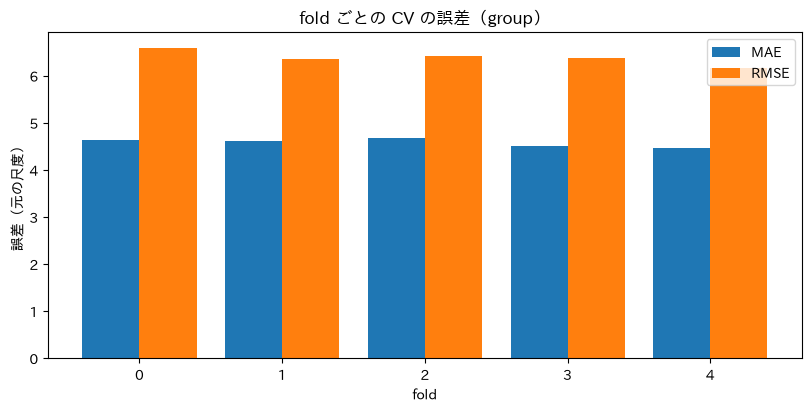

種類ごとの CV の誤差:


,Y_cat,cv_oof_mae,cv_relative_mae
0,Y1,2.6944,0.0429
1,Y2,4.0751,0.0559
2,Y3,7.8870,0.0489
3,Y4,7.0324,0.0503
4,Y5,5.0378,0.0324
5,Y6,3.4368,0.0457
6,Y7,5.3912,0.0463
7,Y8,6.7924,0.0675
8,Y9,2.3005,0.0423
9,Y10,1.0135,0.0641


In [20]:
fold_table = cv_table(run)
scores = cv_result.oof_scores
print(f"CV: {CV_METHOD} / 目的変数の変換: {TARGET_TRANSFORM} / スケーリング: {FEATURE_SCALING}")
print(f"OOF 全体: MAE {scores['mae']:.4f} / RMSE {scores['rmse']:.4f}")
for name in ("MAE", "RMSE"):
    mean, std = fold_table[name].mean(), fold_table[name].std(ddof=0)
    print(f"{name} の fold の平均 ± 標準偏差: {mean:.4f} ± {std:.4f}")
display(fold_table.round(4))
ensure_japanese_font()
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
positions = np.arange(len(fold_table))
ax.bar(positions - 0.2, fold_table["MAE"], 0.4, label="MAE")
ax.bar(positions + 0.2, fold_table["RMSE"], 0.4, label="RMSE")
ax.set_xticks(positions, fold_table["fold"])
ax.set_ylim(bottom=0)  # 棒グラフは0起点
ax.set_xlabel("fold")
ax.set_ylabel("誤差（元の尺度）")
ax.set_title(f"fold ごとの CV の誤差（{CV_METHOD}）")
ax.legend(loc="upper right")
plt.show()
plt.close(fig)
print("種類ごとの CV の誤差:")
summary.round(4)

- **種類ごとの誤差:** 種類ごとの CV の相対MAE。
- **学習結果:** 種類ごとの実測値（黒）と OOF 予測（赤）。
- **テスト結果:** 種類ごとの 2025年の予測（正解が無いので実測は無い）。

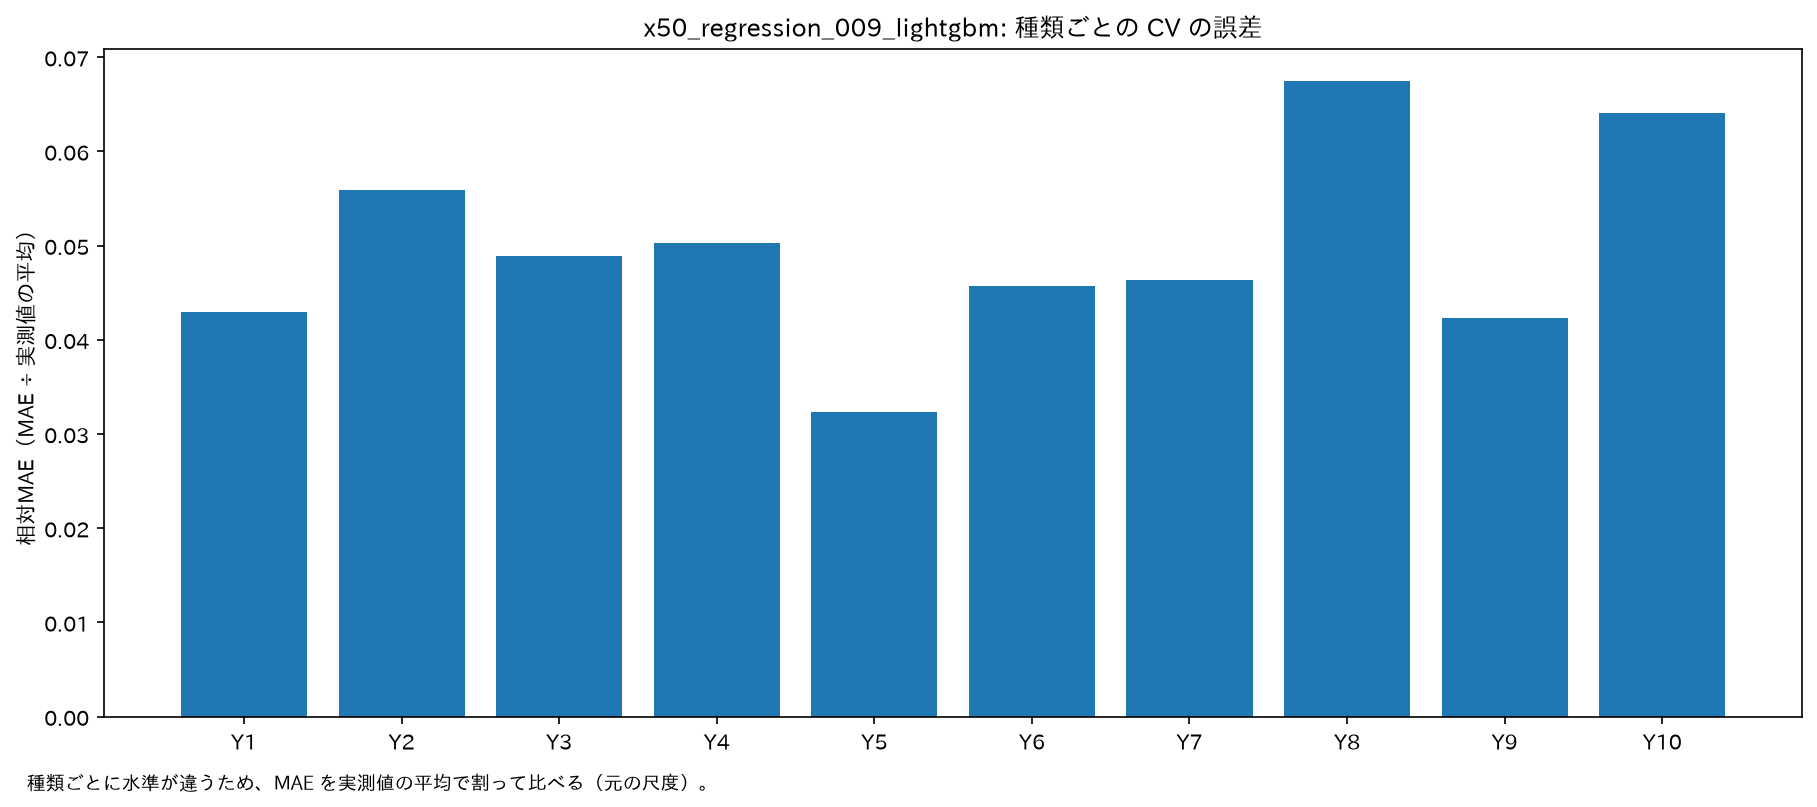

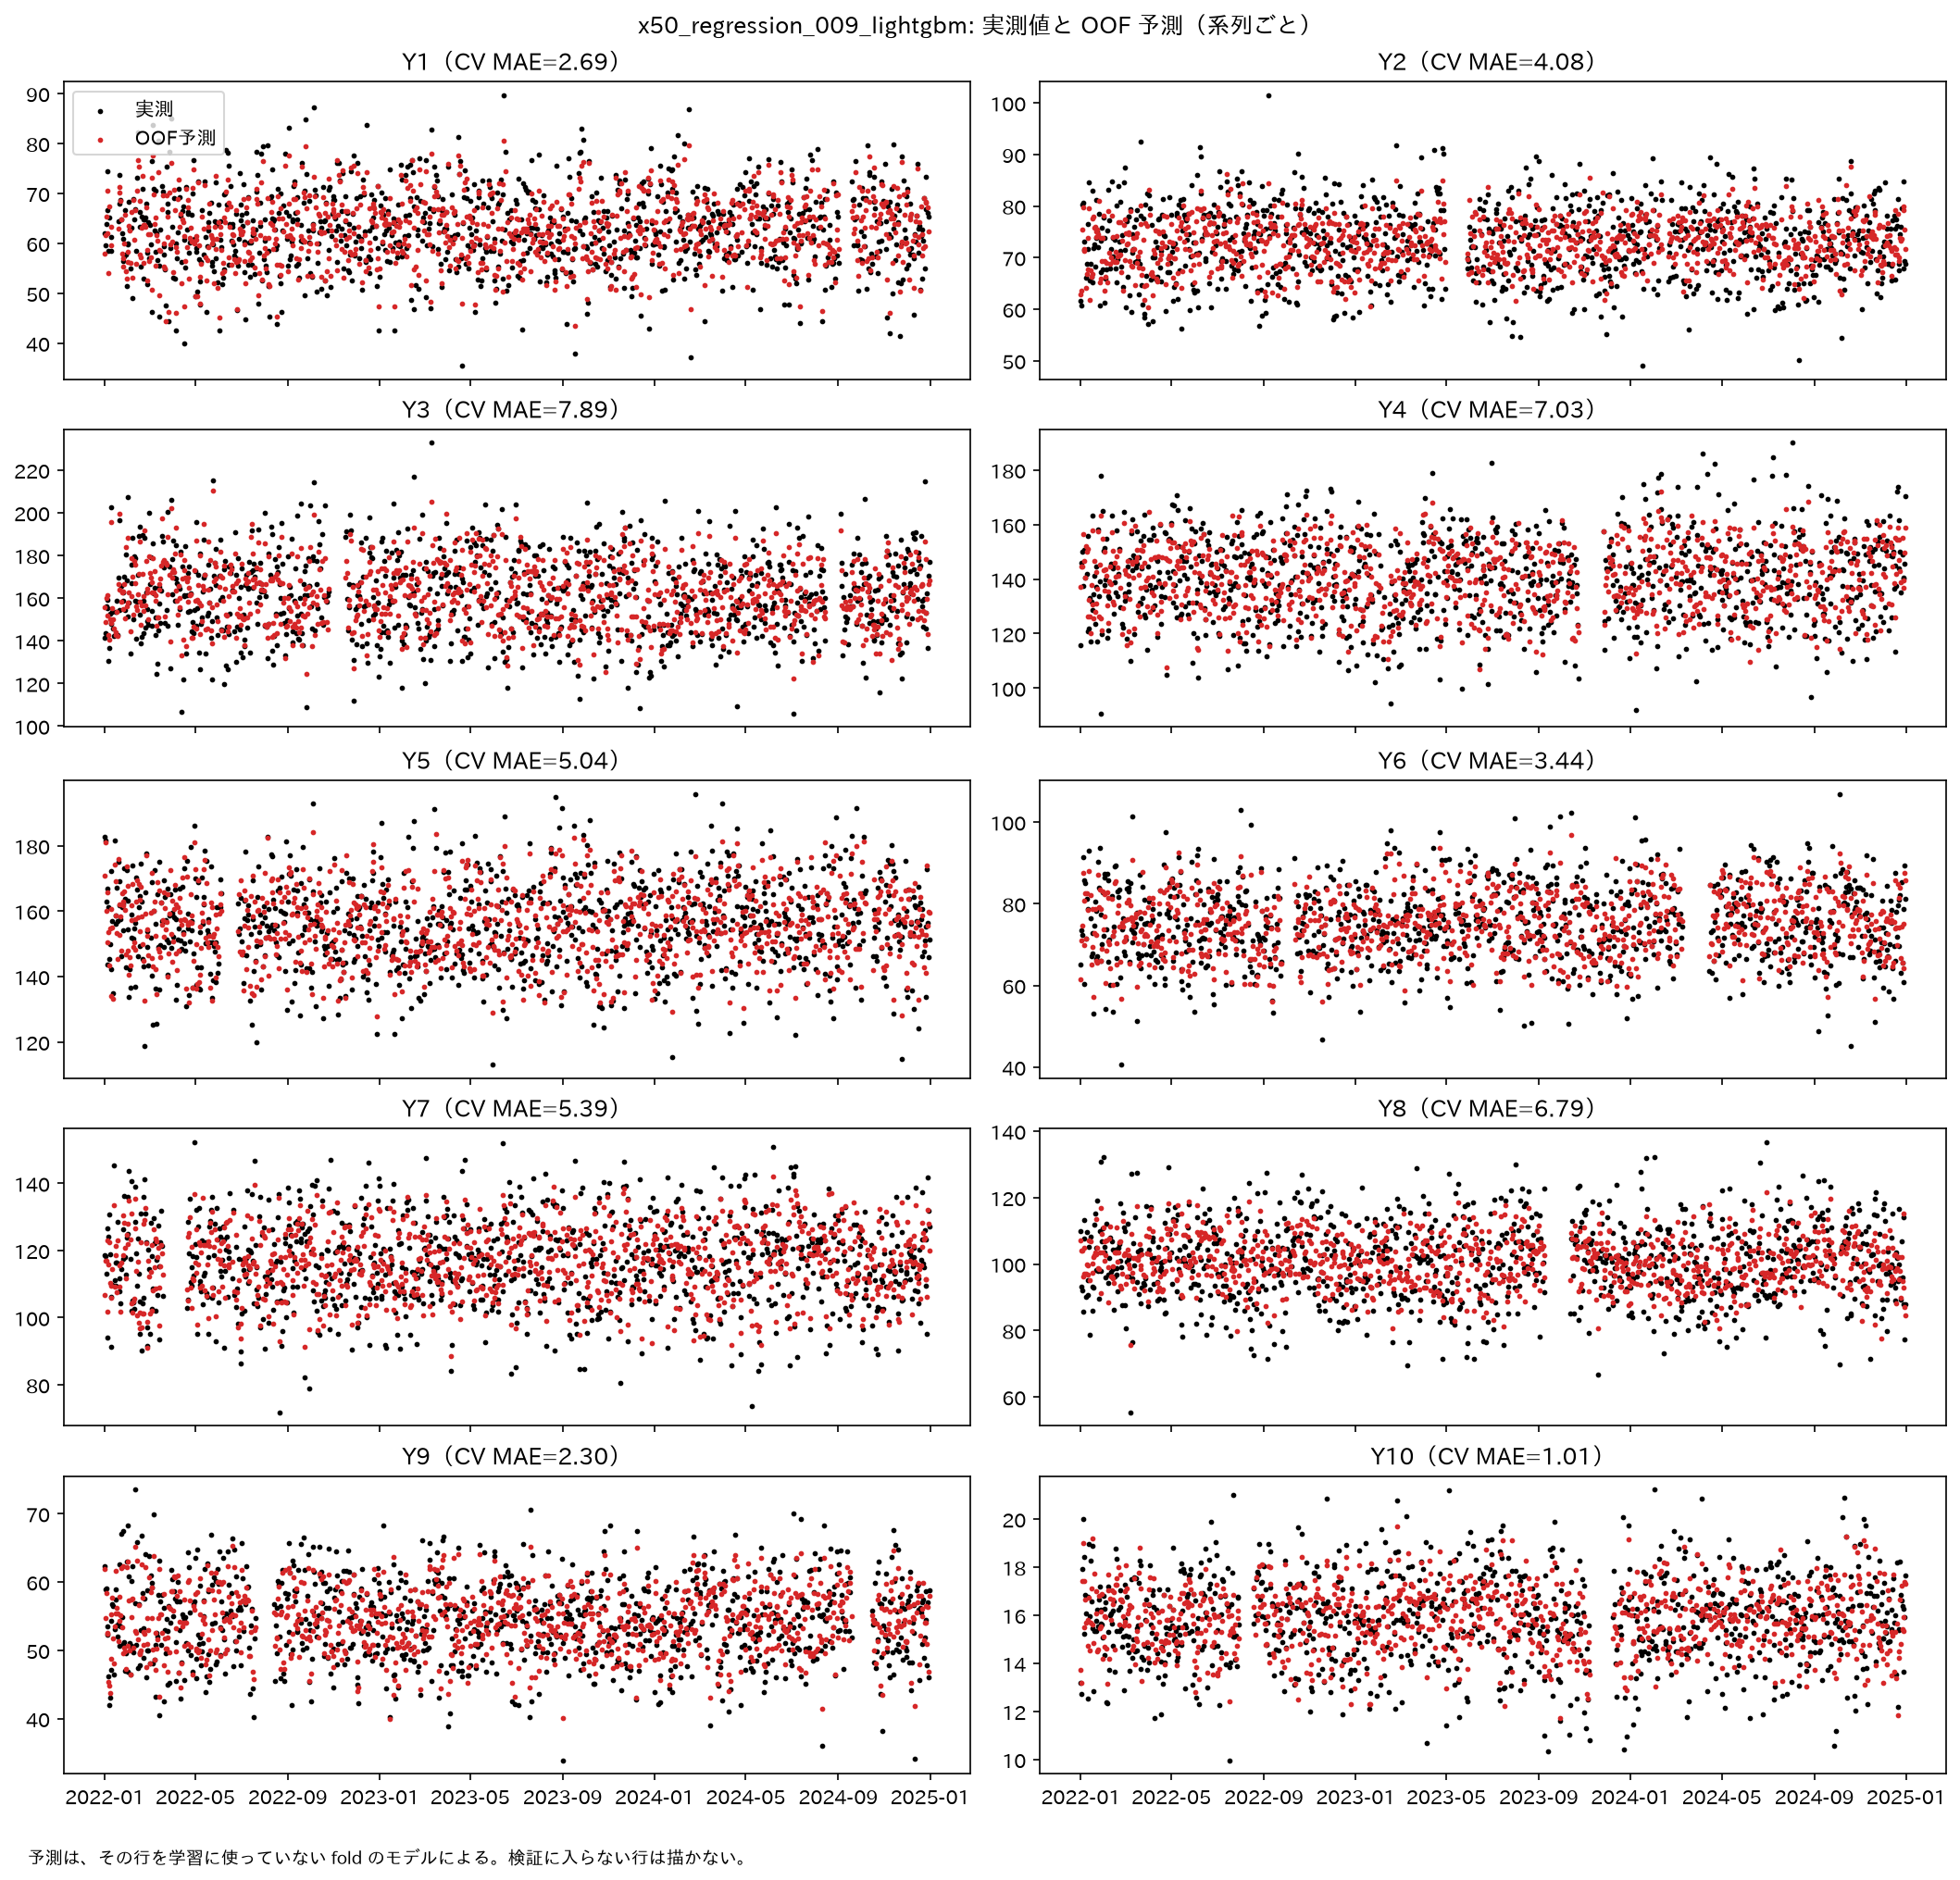

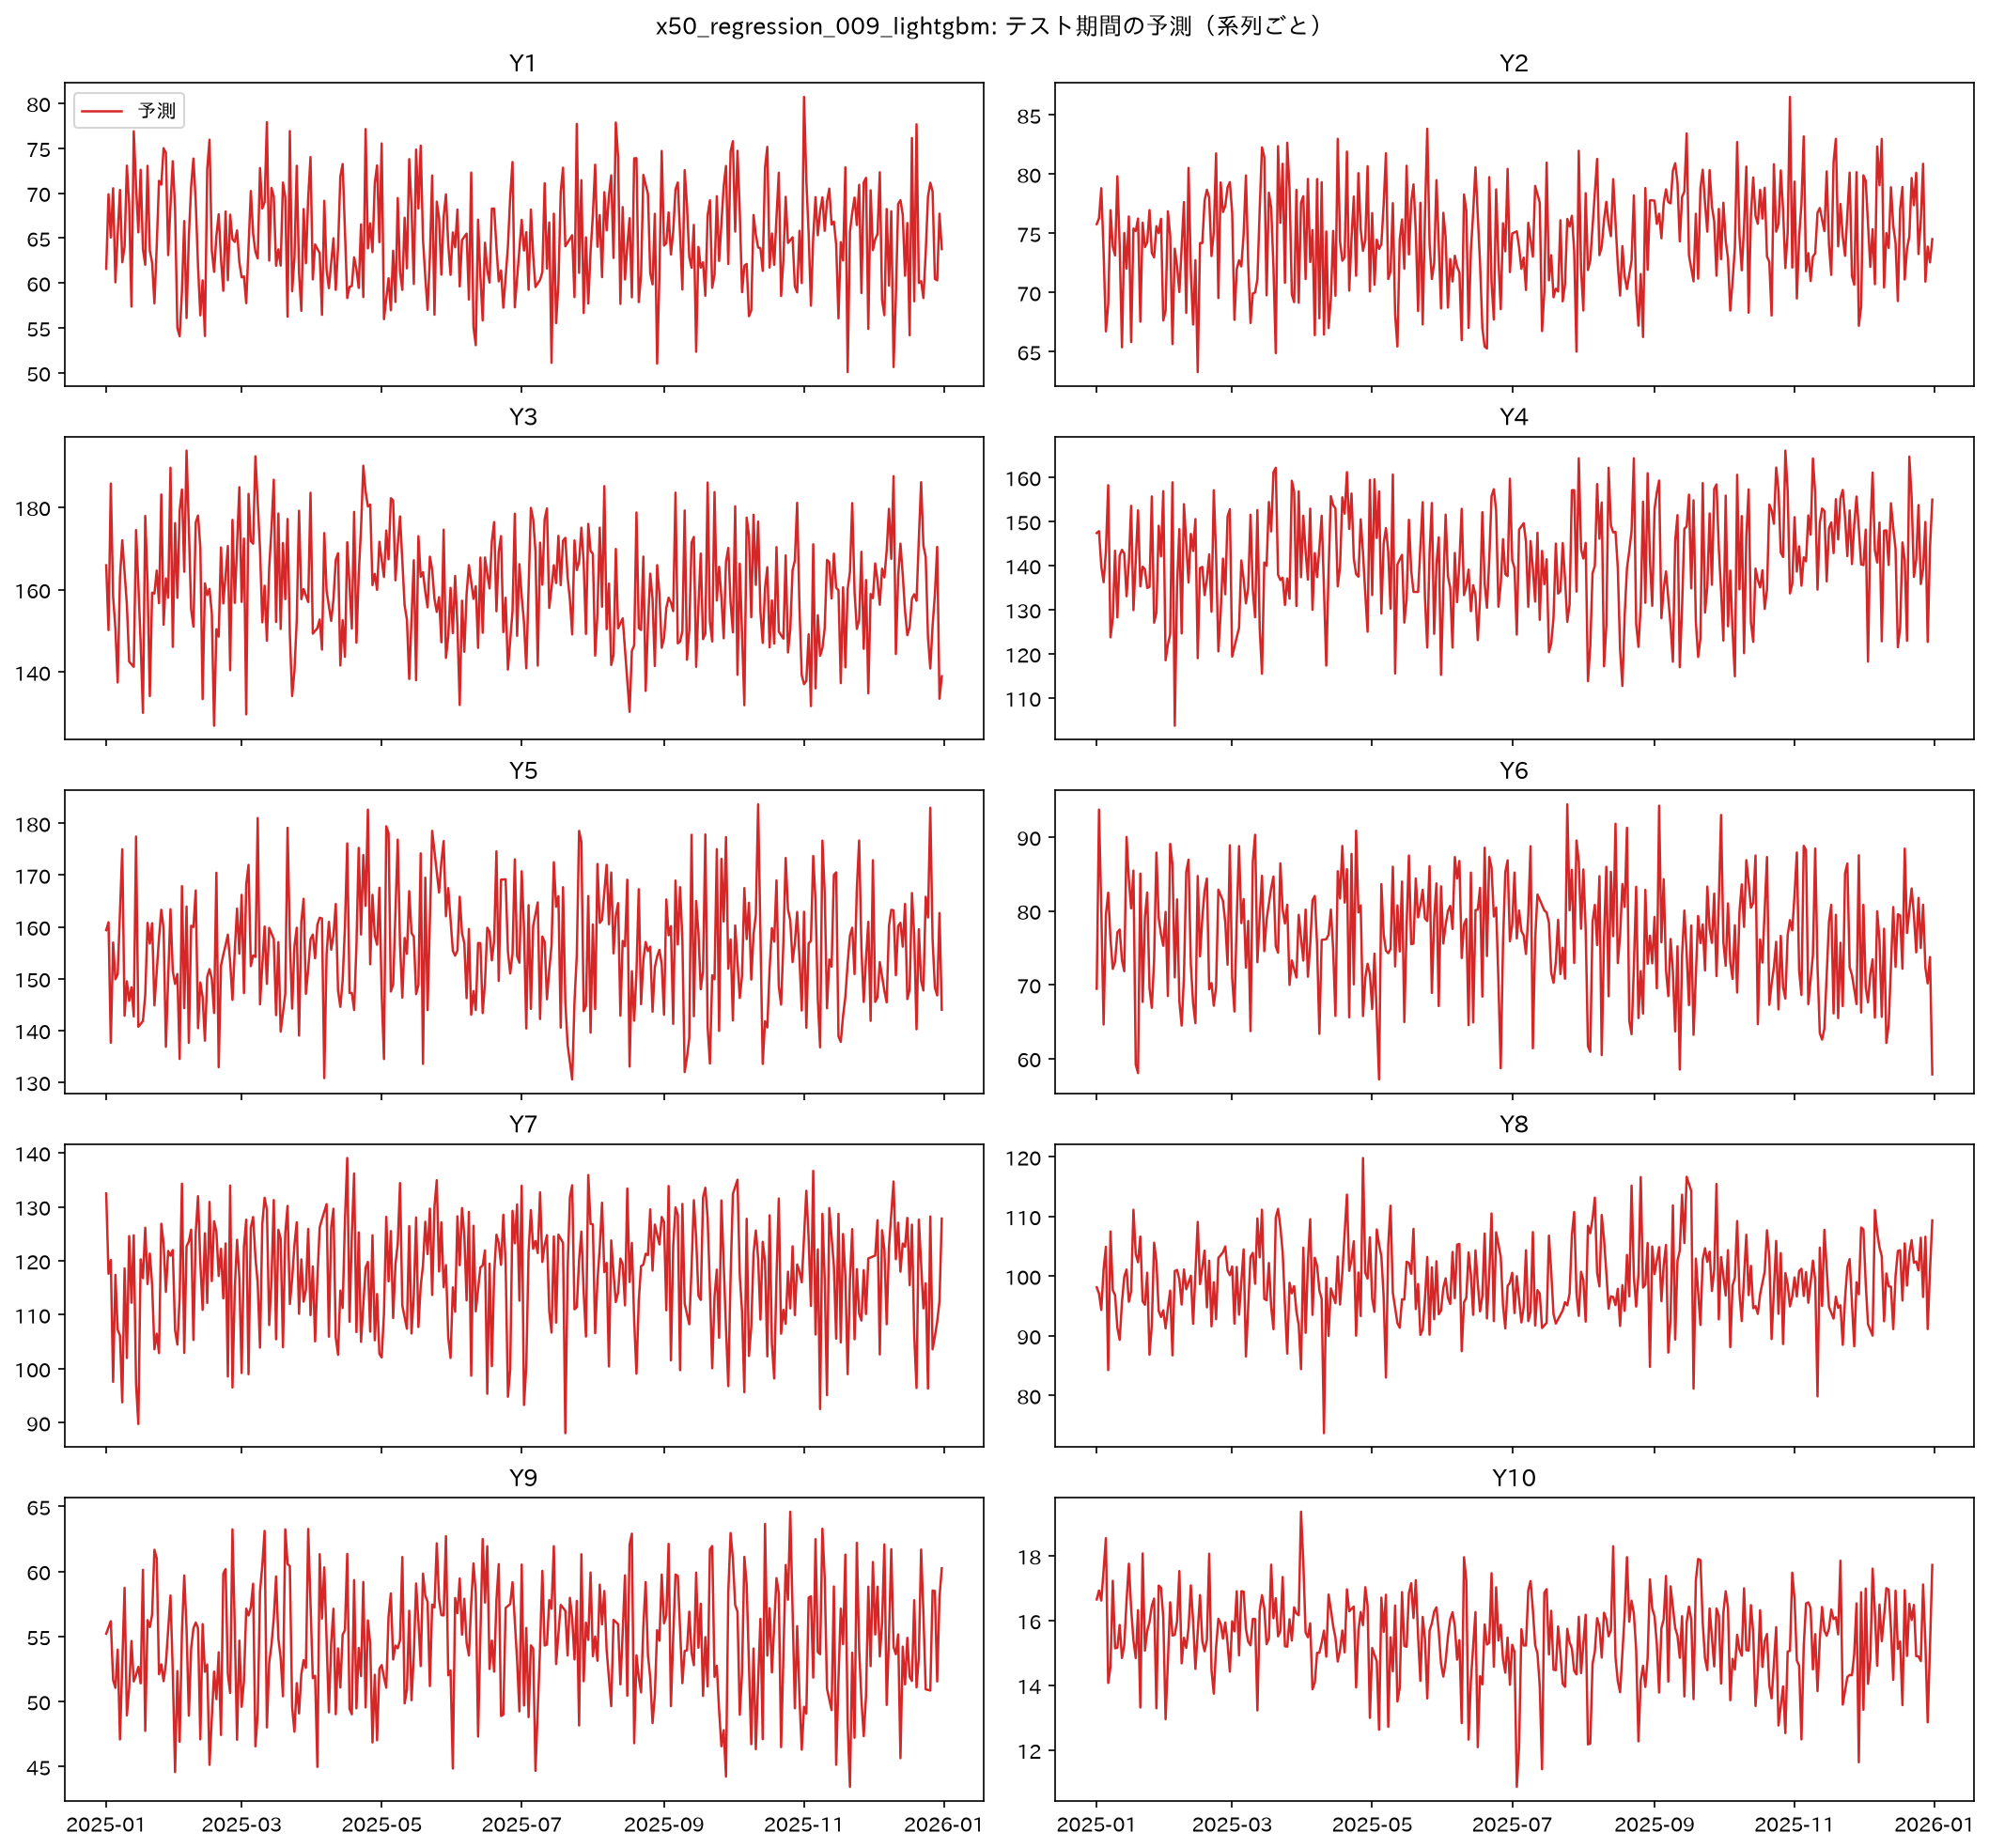

In [21]:
figures = out / "figures"
display(Image(filename=str(figures / "summary_mae.png"), width=950))
display(Image(filename=str(figures / "training_overview.png"), width=1000))
display(Image(filename=str(figures / "test_overview.png"), width=1000))

## 9. SHAP によるモデル解釈

モデルを、各 fold の検証側のデータで説明した SHAP 値（OOF SHAP）。SHAP 値はモデルの尺度（目的変数を変換した場合は
変換後の尺度）。`Y_cat` は系列ID。

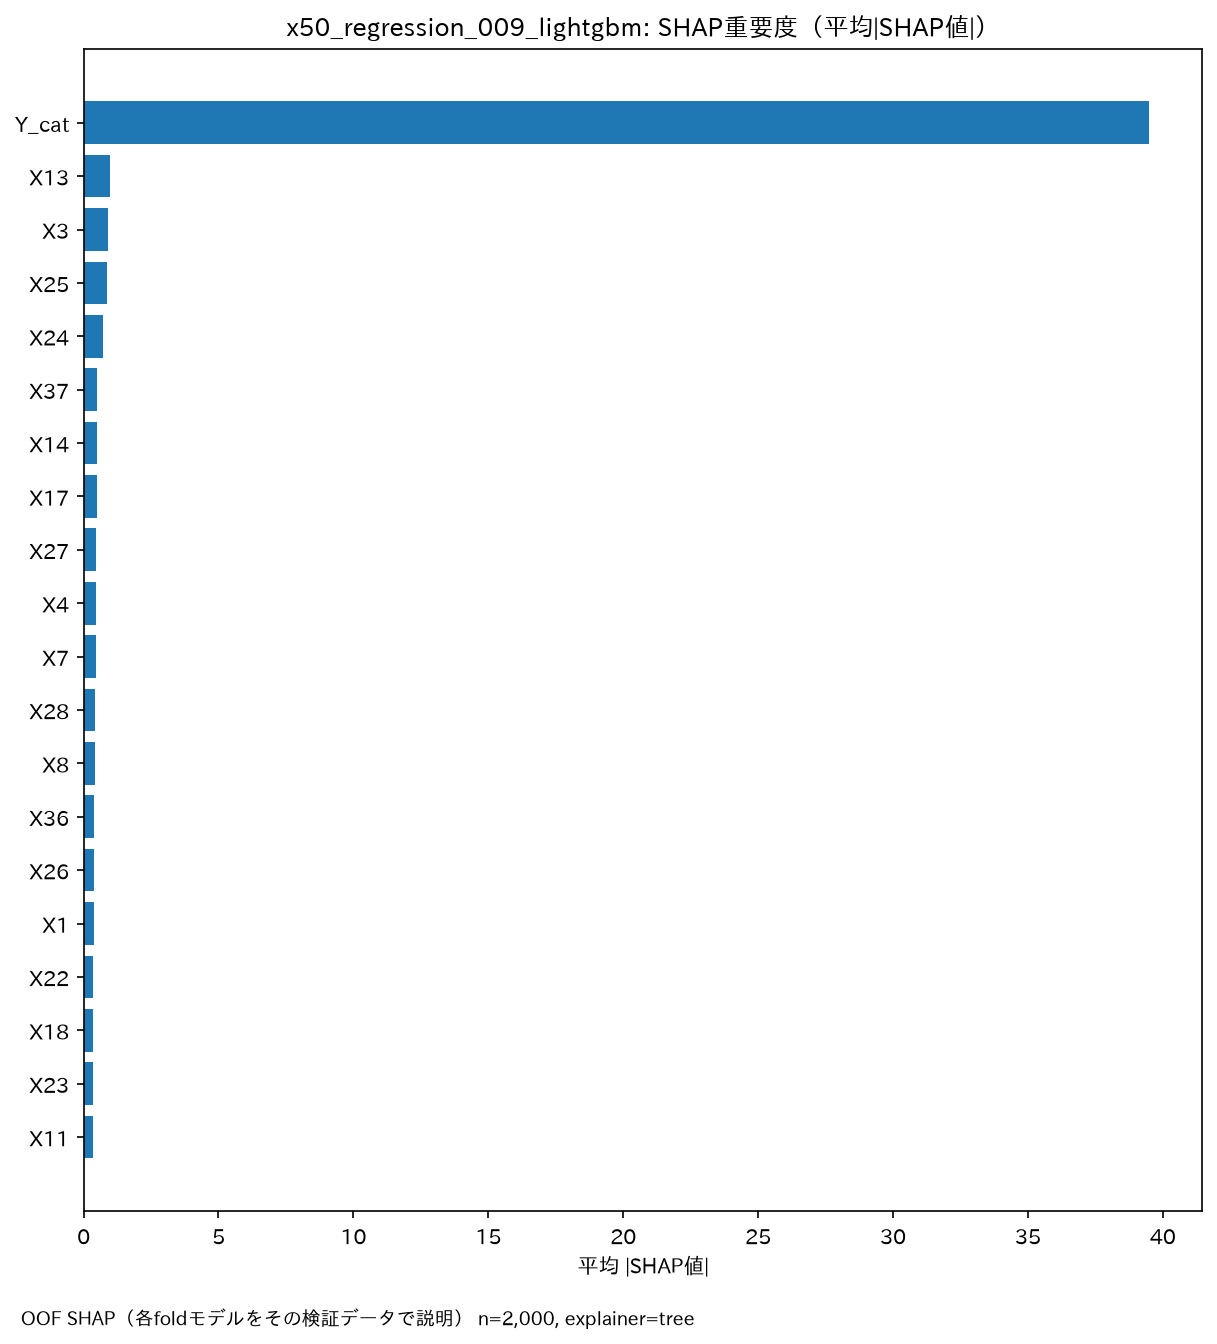

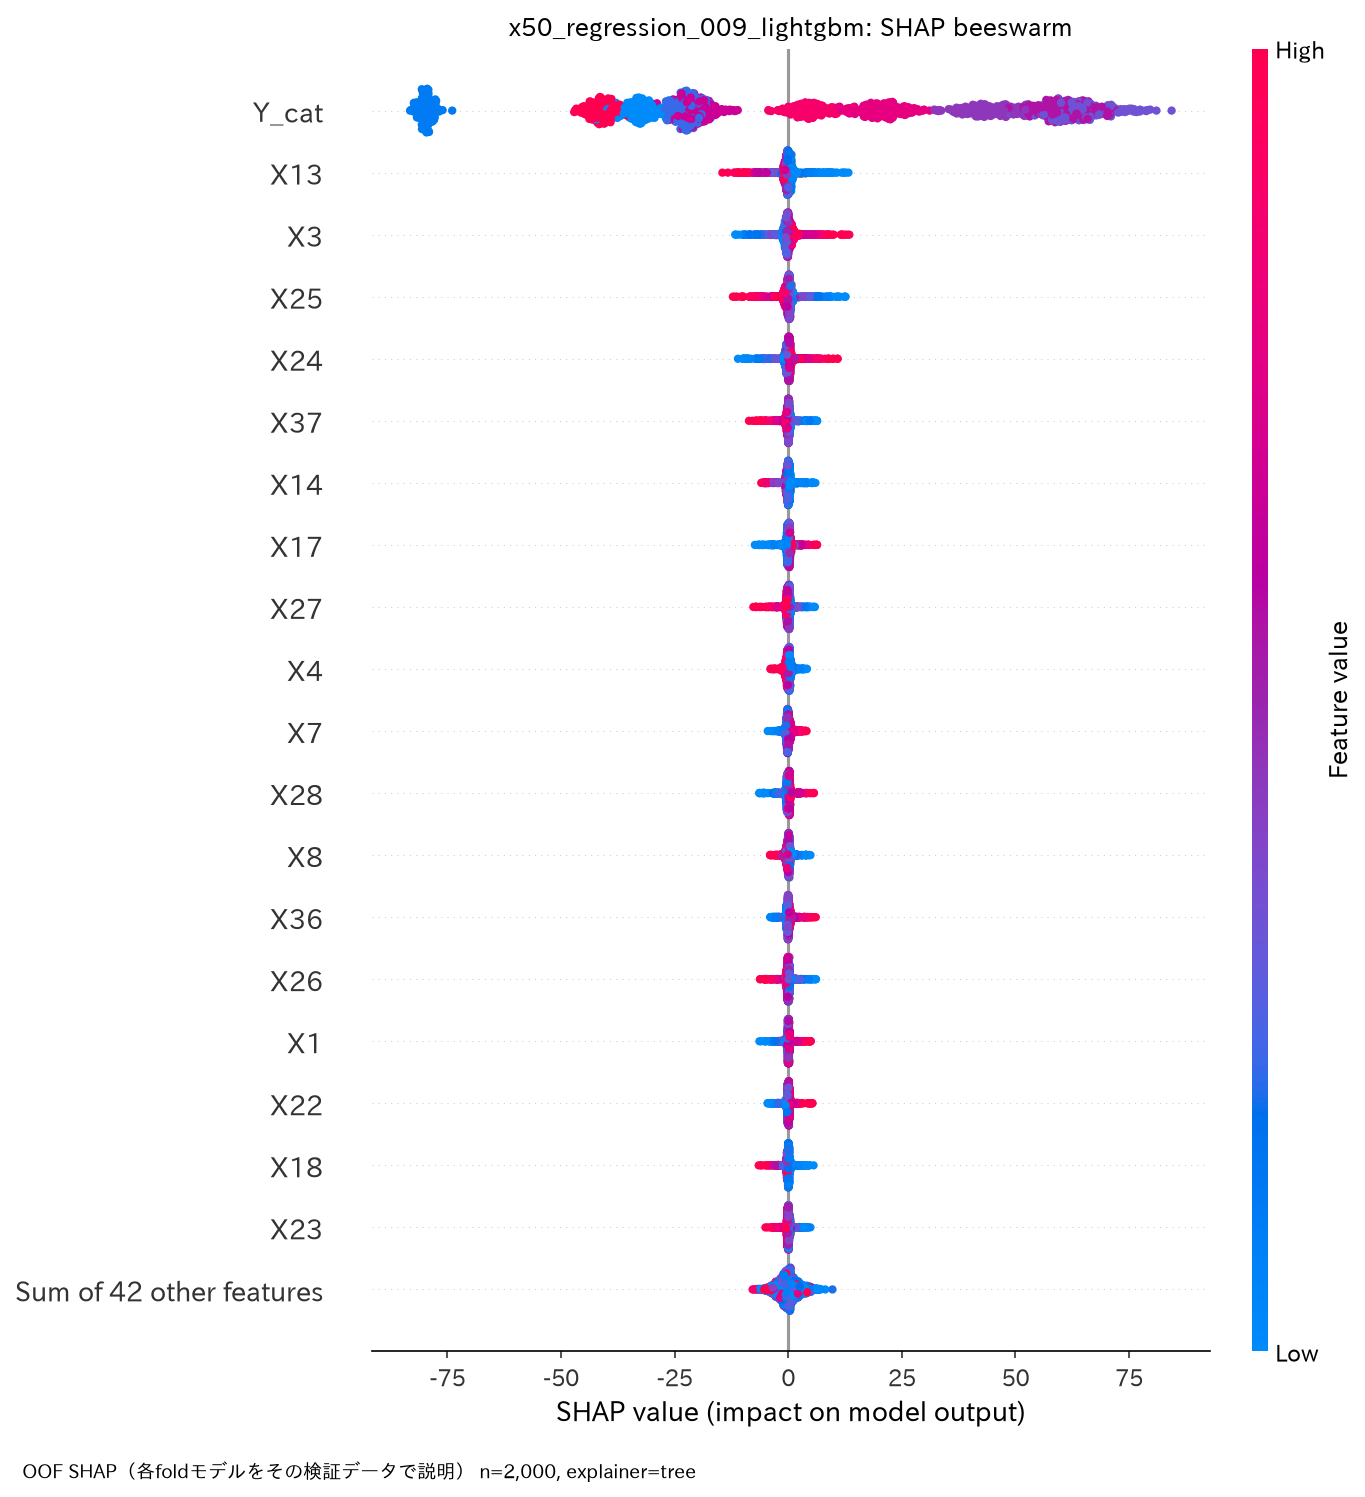

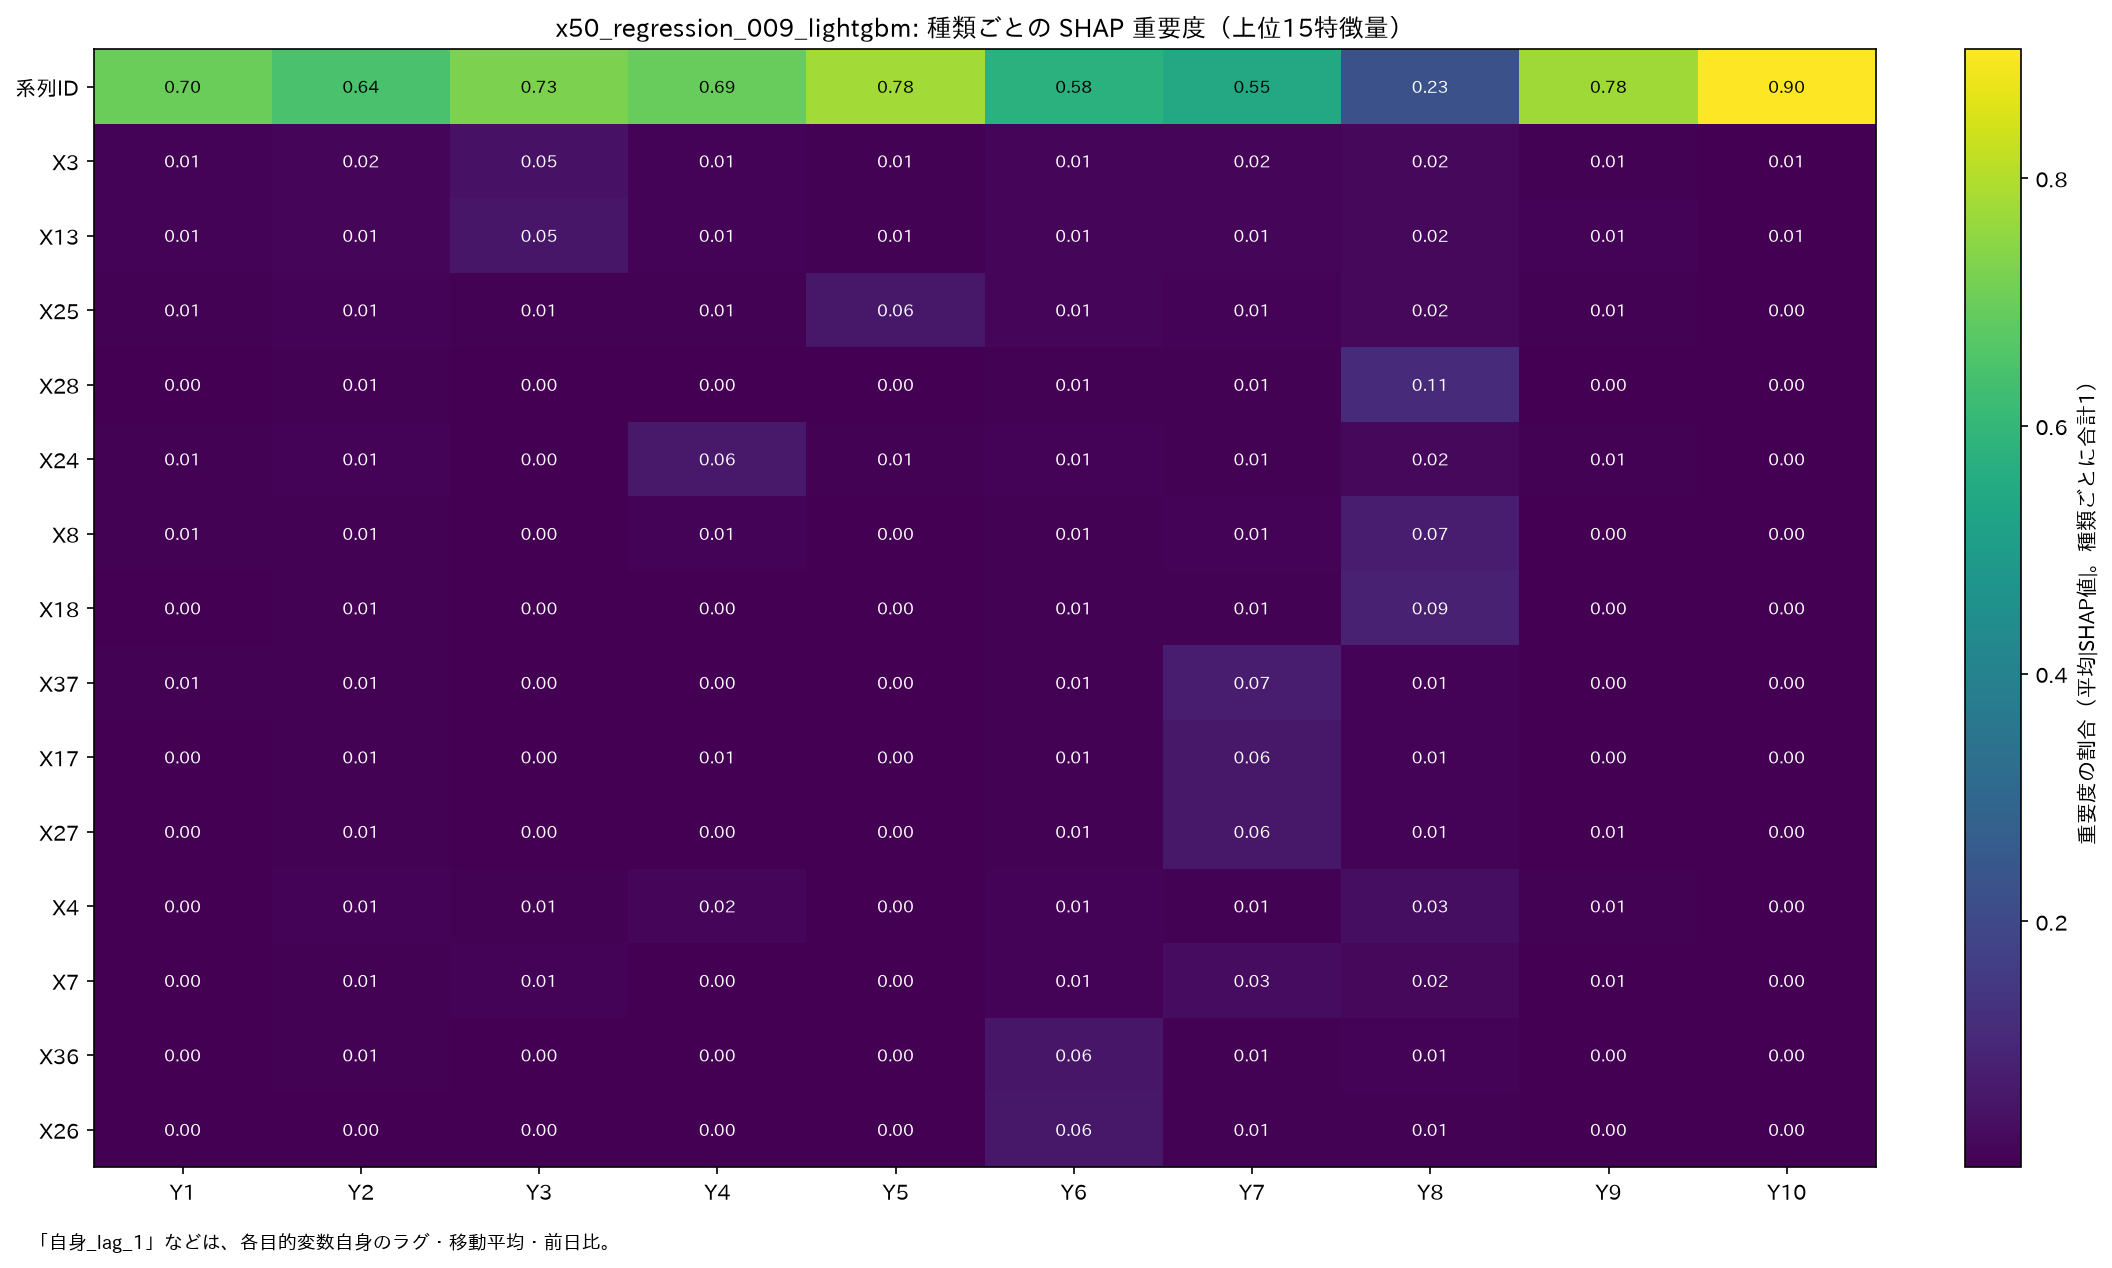

In [22]:
shap_dir = out / "shap"
display(Image(filename=str(shap_dir / "shap_importance_bar.png"), width=700))
display(Image(filename=str(shap_dir / "shap_beeswarm.png"), width=800))
display(Image(filename=str(figures / "shap_overview.png"), width=1000))

## 10. 残差解析

OOF 予測の残差（実測 − 予測。元の尺度）を調べる。

### 残差の要約

全体と種類ごとの、残差の平均（偏り）・標準偏差など。

In [23]:
evaluation_dir = out / EVALUATION_DIR
predicted = run.oof[run.oof["fold"] >= 0]
groups = {
    str(cat): (part[ACTUAL_COL].to_numpy(), part[PRED_COL].to_numpy())
    for cat, part in predicted.groupby(CAT_COL, sort=False)
}
residual_table = pd.DataFrame(
    [
        {CAT_COL: "全体", **residual_summary(predicted[ACTUAL_COL], predicted[PRED_COL])},
        *[{CAT_COL: cat, **residual_summary(*pair)} for cat, pair in groups.items()],
    ]
)
residual_table.to_csv(evaluation_dir / "residual_summary_by_category.csv", index=False)
display(residual_table.round(4))

,Y_cat,n,mean,std,skewness,excess_kurtosis,mae,rmse
0,全体,10061.0,-0.0070,6.3845,-0.0561,2.2263,4.5732,6.3841
1,Y1,1017.0,0.1465,3.4748,-0.0192,0.6824,2.6944,3.4762
2,Y2,1009.0,0.0527,5.0745,-0.0430,-0.0593,4.0751,5.0723
3,Y3,1005.0,-0.0933,10.0287,0.0460,0.1975,7.8870,10.0241
4,Y4,1007.0,-0.1038,8.9014,0.0056,0.2952,7.0324,8.8976
5,Y5,1016.0,-0.1441,6.4579,0.0621,0.8420,5.0378,6.4563
6,Y6,997.0,0.0510,4.4050,-0.2246,1.1495,3.4368,4.4031
7,Y7,1014.0,-0.0517,6.7688,-0.2361,0.3259,5.3912,6.7657
8,Y8,1007.0,0.0170,8.5162,-0.1039,0.0265,6.7924,8.5120
9,Y9,997.0,0.0743,2.9026,0.0729,-0.0083,2.3005,2.9021


### 誤差曲線

各 fold の、反復（木の本数）ごとの学習・検証の損失。検証の損失が下がらなくなる所で early stopping が止まる。
学習と検証の差が大きいと過学習。モデルの尺度の値。`LEARNING_CURVE = True` なら、学習データの量を変えた学習曲線も表示する。

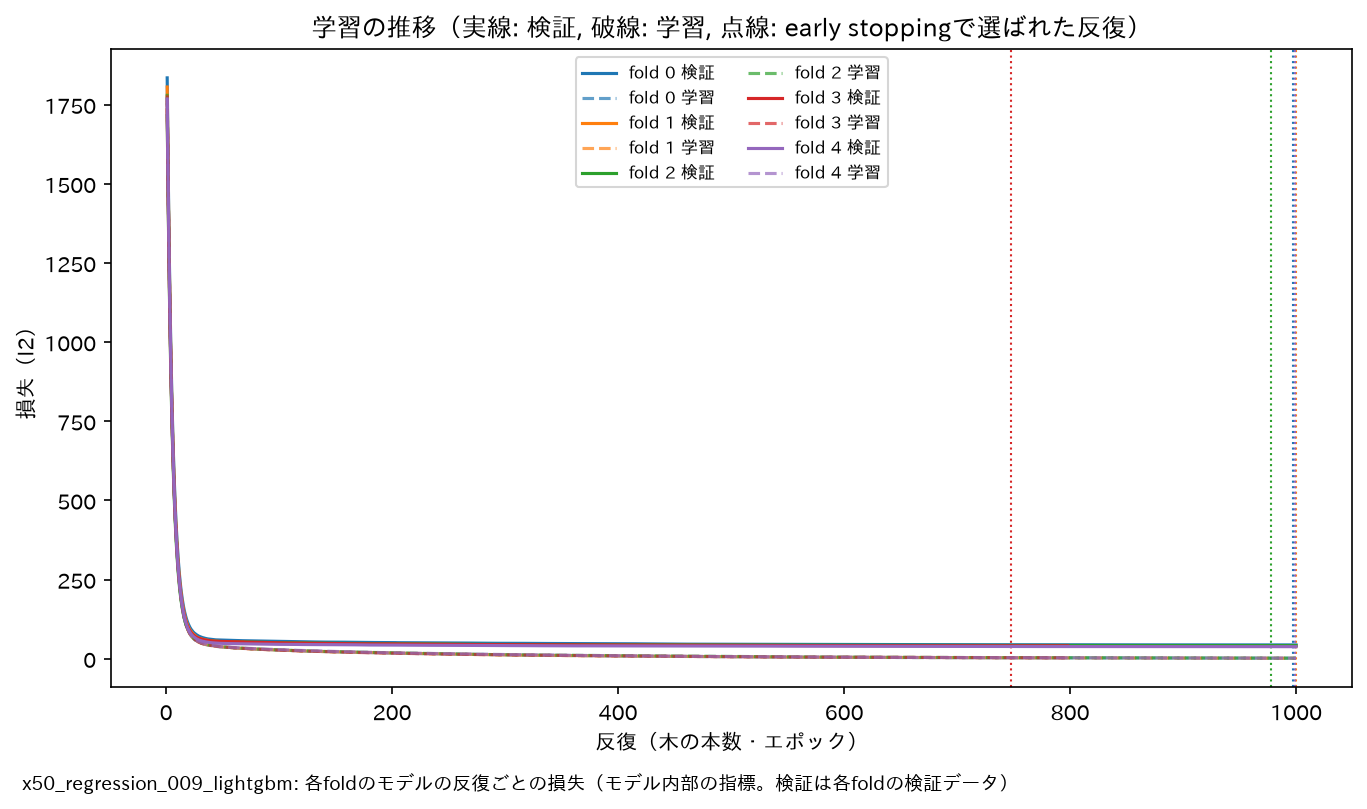

In [24]:
display(Image(filename=str(evaluation_dir / "training_history.png"), width=800))
learning_curve_path = evaluation_dir / "learning_curve.png"
if learning_curve_path.is_file():
    display(Image(filename=str(learning_curve_path), width=800))

### 誤差分布

- **残差の分布:** 山が0からずれていると偏りがある。全体の分布は種類をまとめたものなので、尺度の違いで裾が重く見える。
- **Q-Q プロット:** 点が直線から離れるほど、正規分布から外れている。
- **残差プロット:** 予測値が大きいほど残差が広がるなら、誤差が水準に比例している（対数の変換を試す目安）。
- **種類ごとの分布:** 尺度の違いの影響を除いて、種類ごとの分布の形を見る。

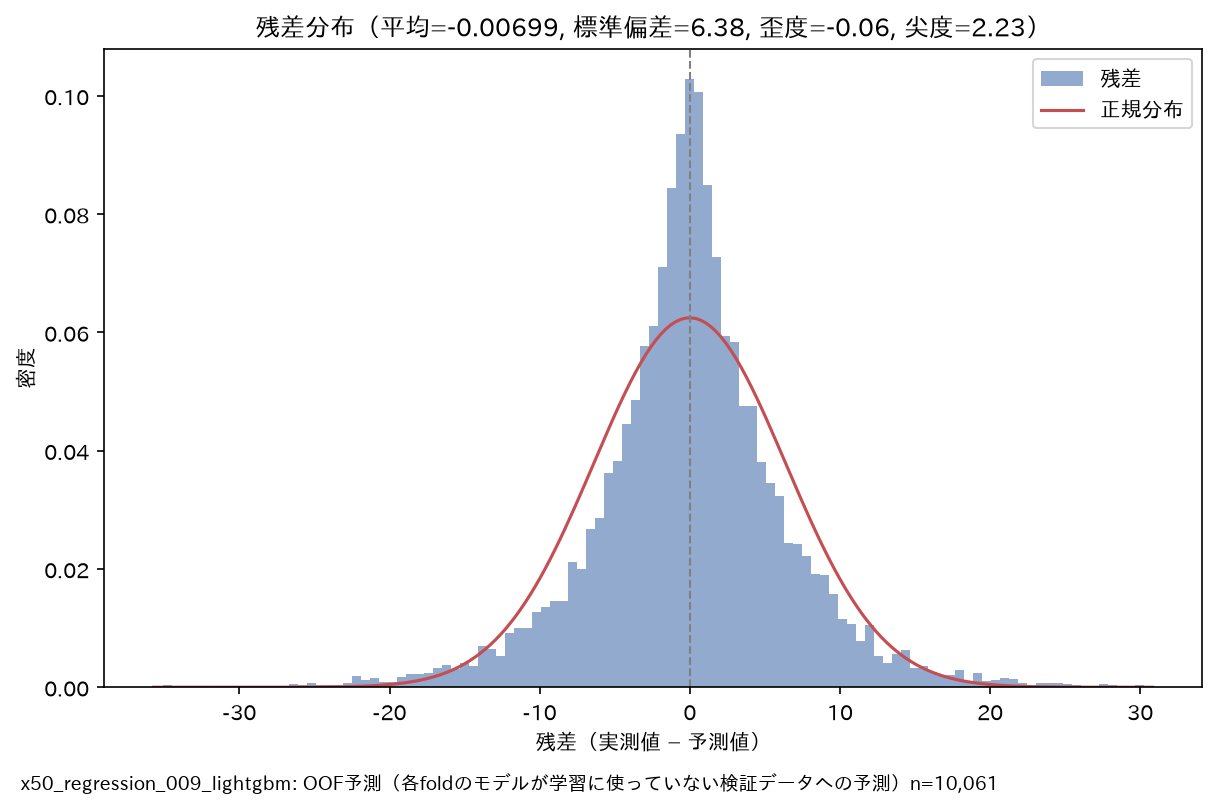

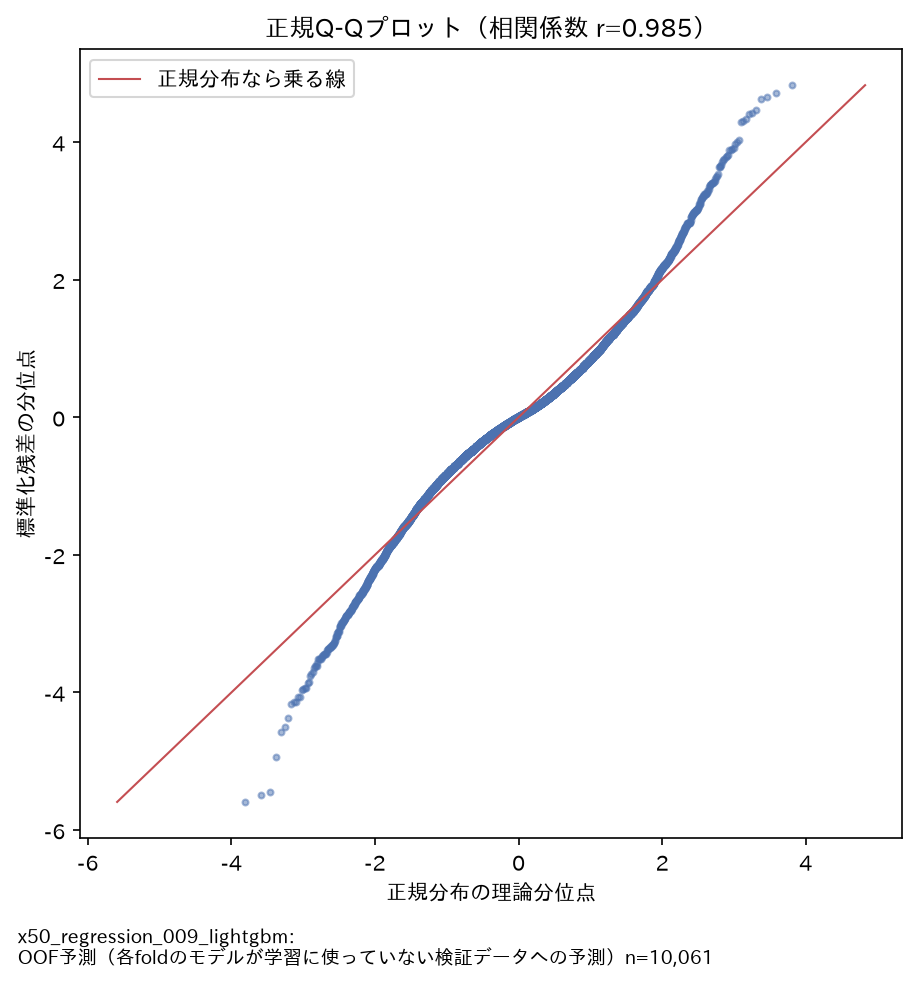

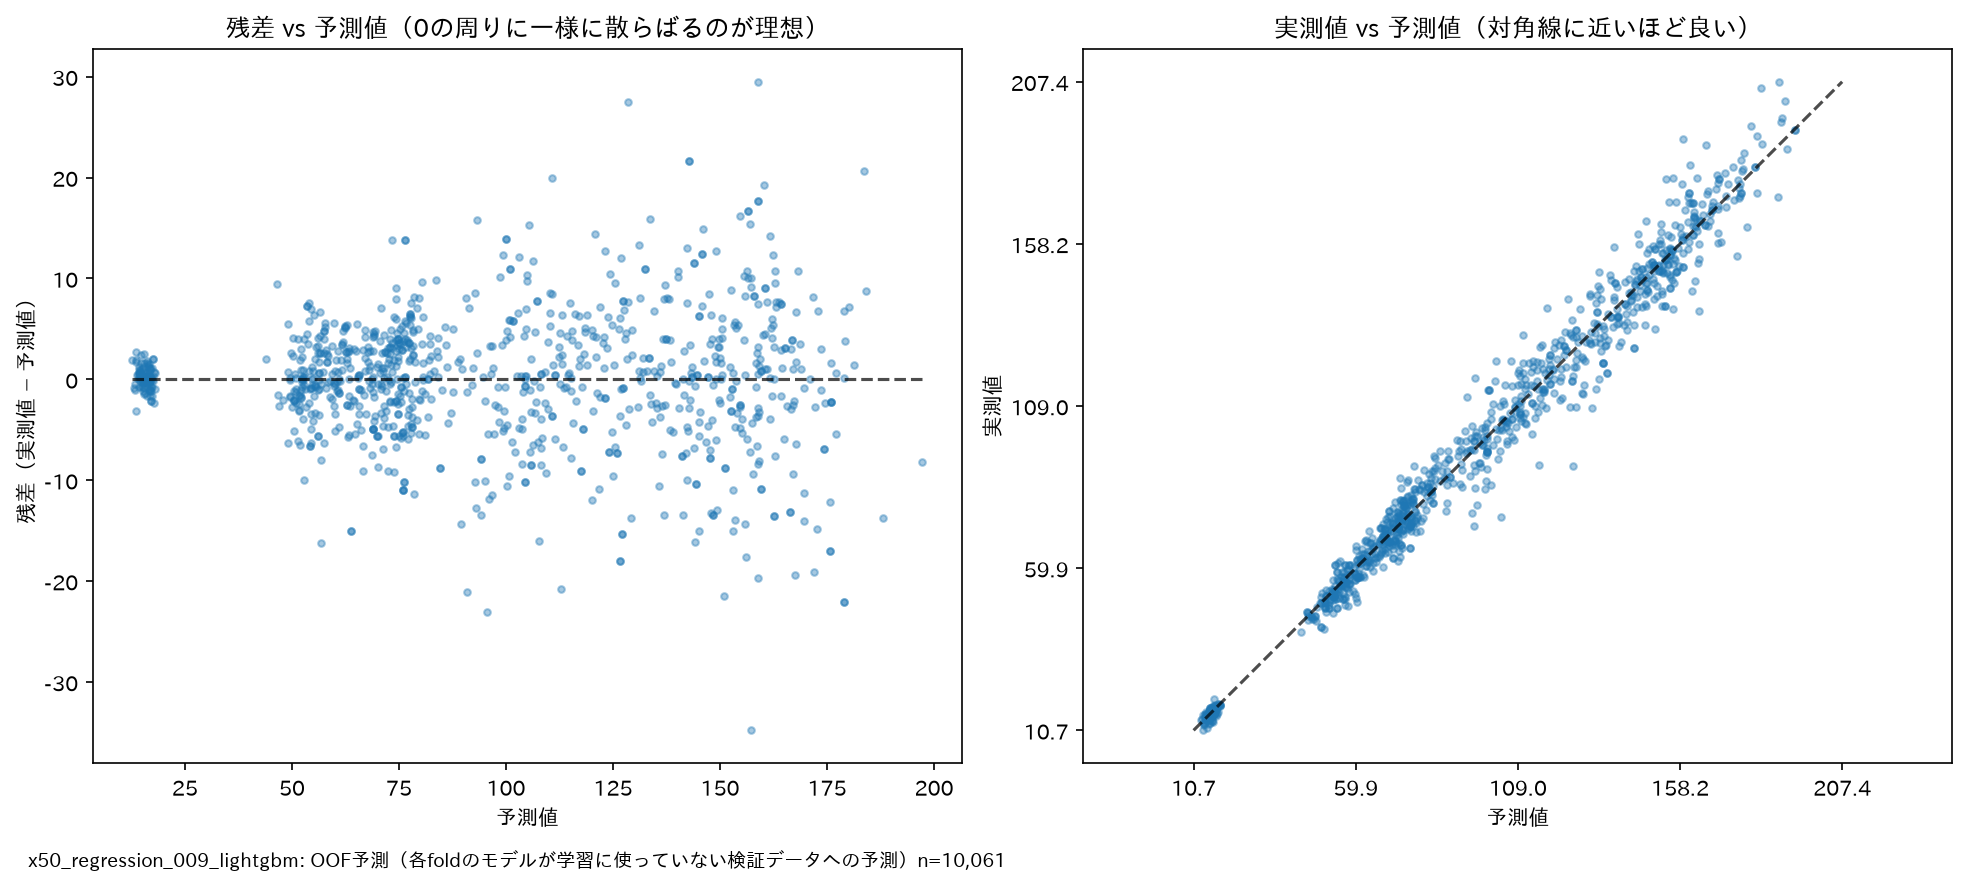

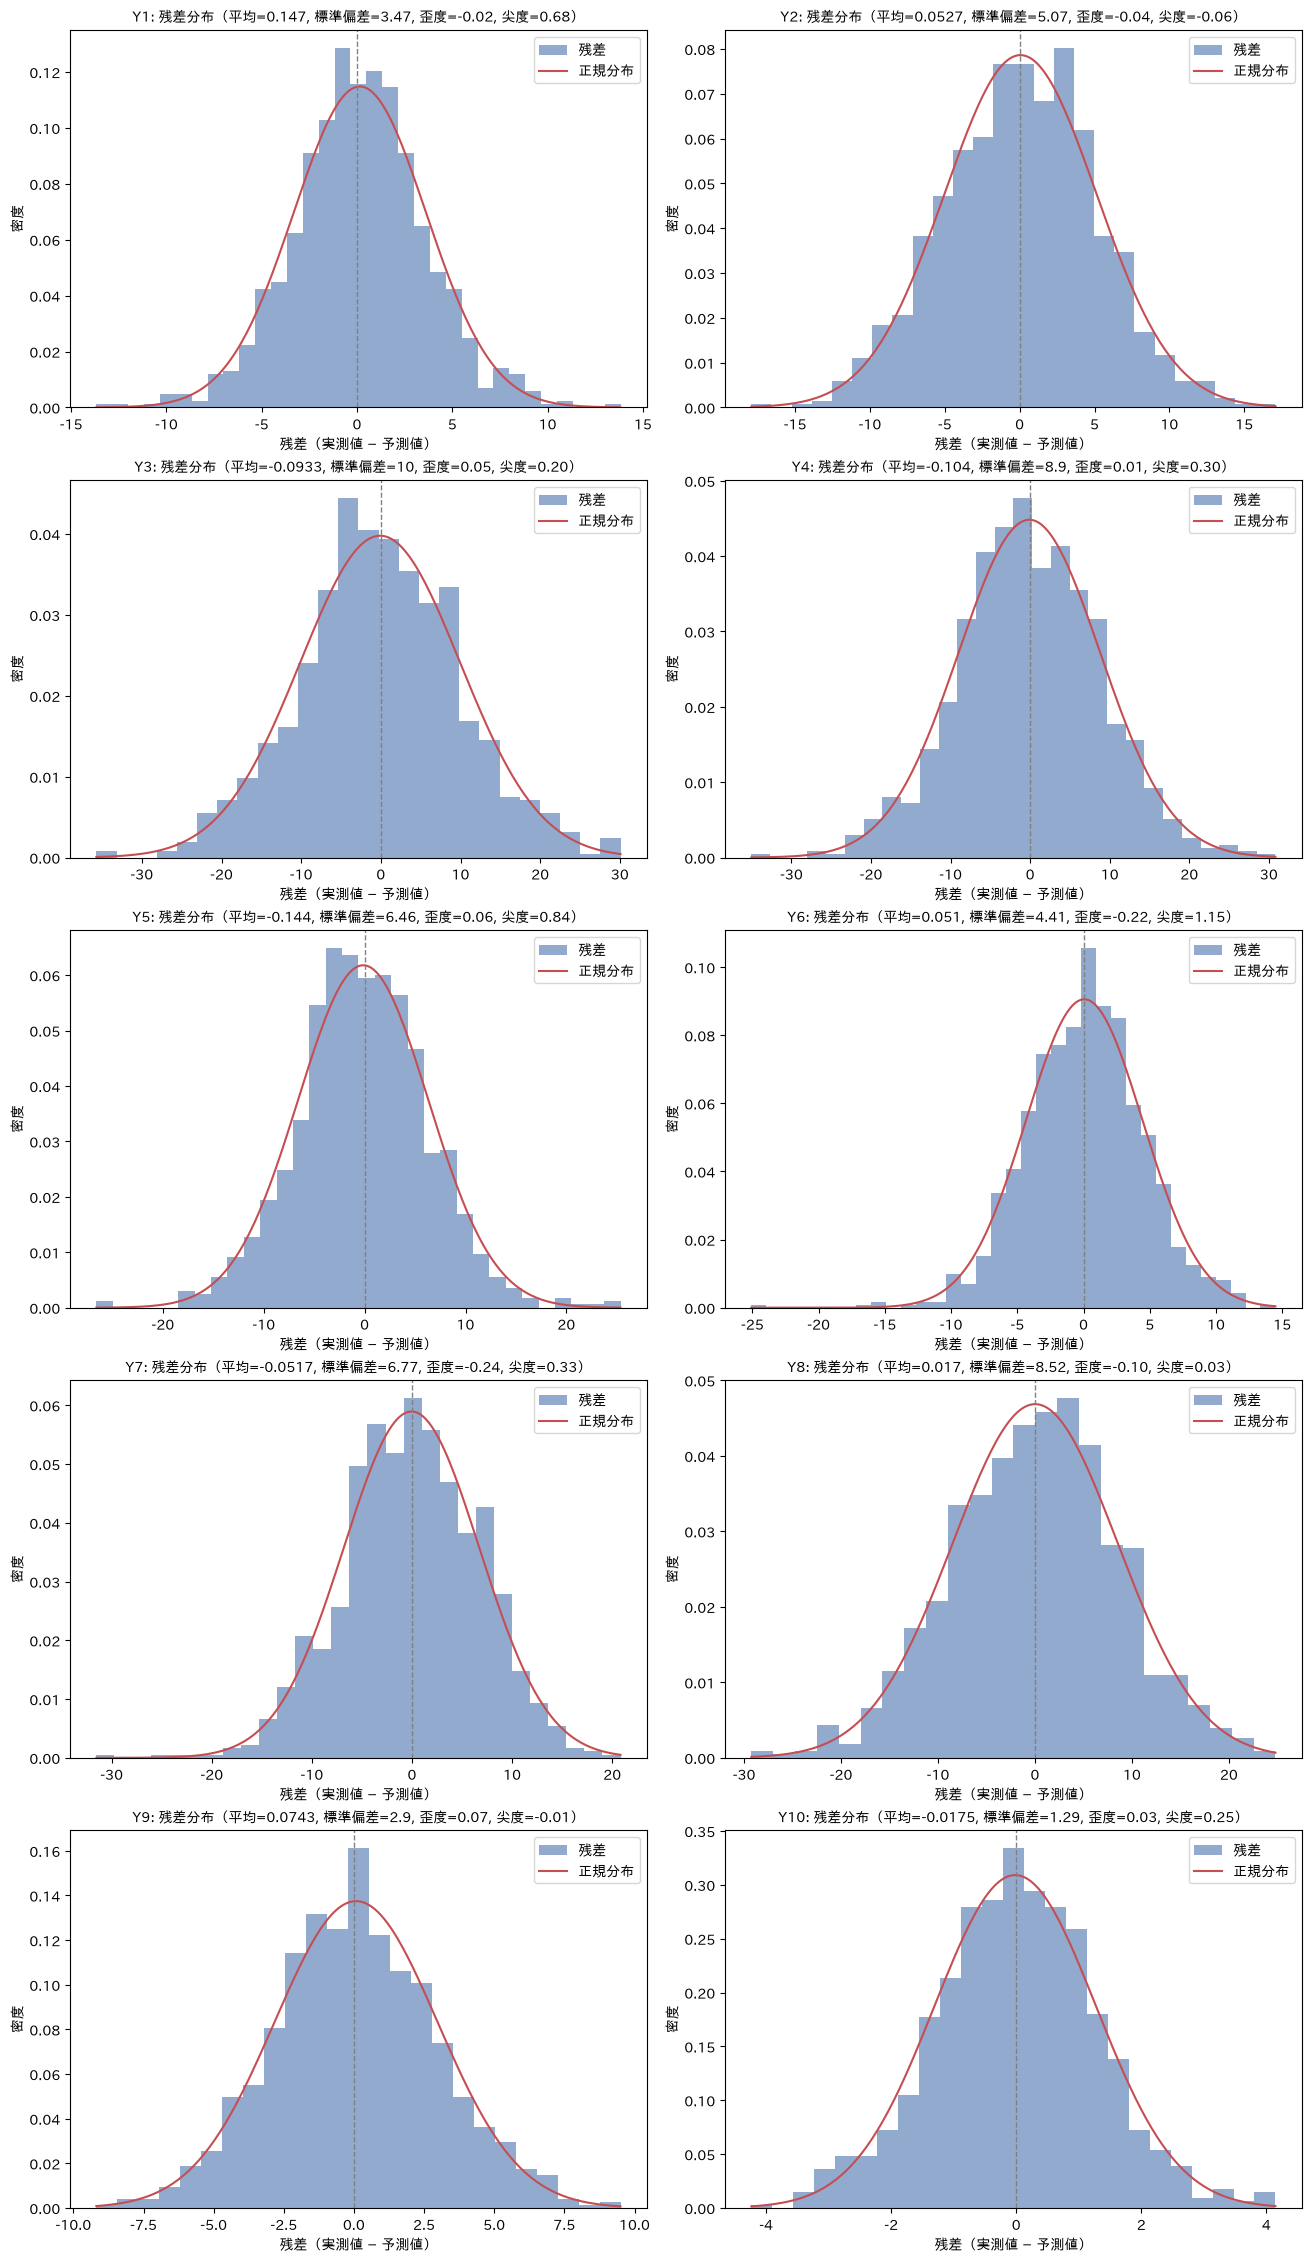

In [25]:
display(Image(filename=str(evaluation_dir / "residual_distribution.png"), width=800))
display(Image(filename=str(evaluation_dir / "qq_plot.png"), width=650))
display(Image(filename=str(evaluation_dir / "residual_plot.png"), width=800))
fig, _ = plot_residuals_by_group("distribution", groups)
fig.savefig(evaluation_dir / "residual_distribution_by_category.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

### 影響の大きい行

Leverage と Cook's distance。線形回帰の診断量なので、木のモデルでは影響の大きい行の目安として見る。

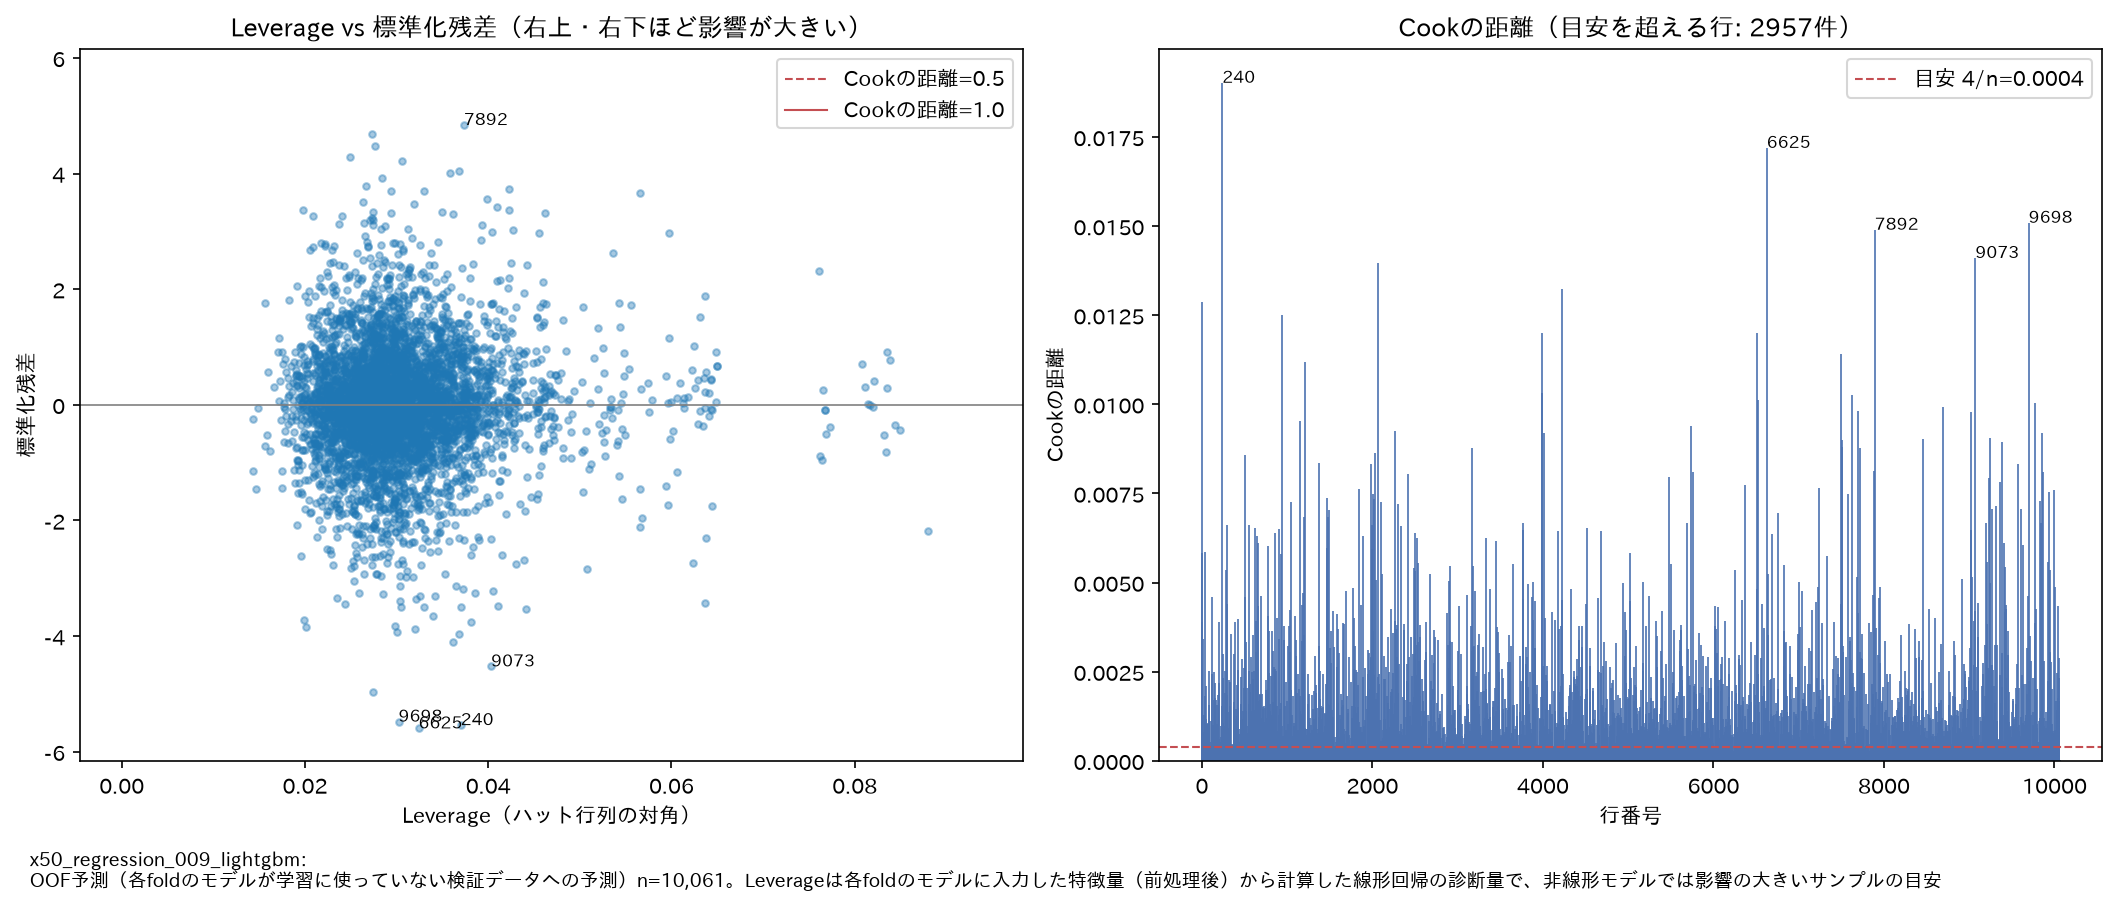

In [26]:
influence_path = evaluation_dir / "leverage_cooks_distance.png"
if influence_path.is_file():
    display(Image(filename=str(influence_path), width=950))

## 11. 1つの種類の詳細（`DETAIL_TARGET`）

残差の推移と自己相関（ACF / PACF）。残差に自己相関が残っていれば、モデルが取りこぼした時間の構造がある。

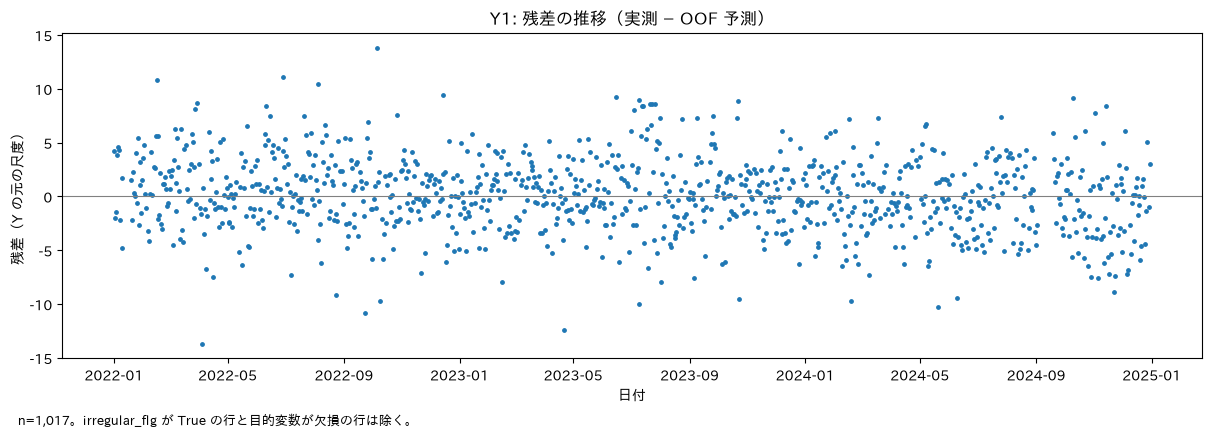

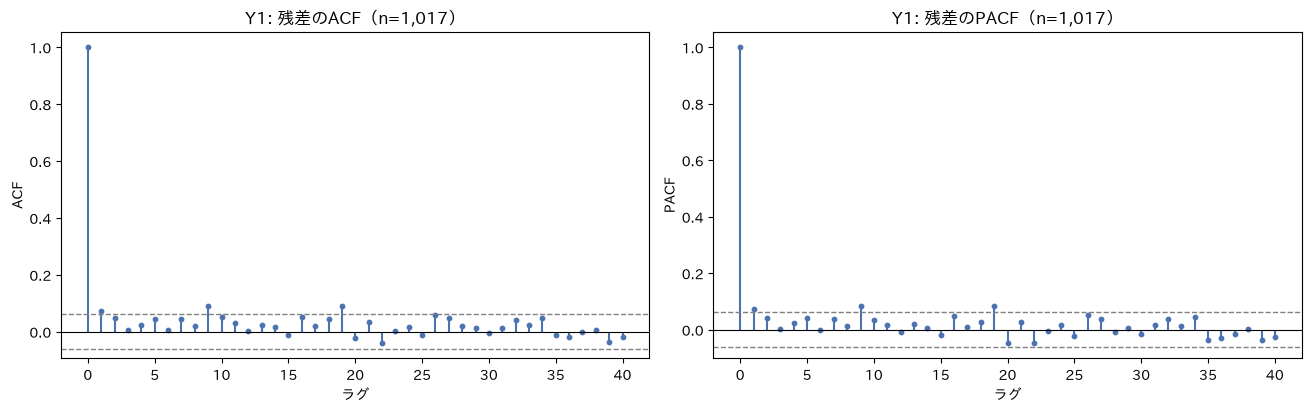

,date,Y_cat,pred
0,2025-01-01,Y1,61.578522
10,2025-01-02,Y1,69.885334
19,2025-01-03,Y1,65.067311
29,2025-01-04,Y1,70.551122
39,2025-01-05,Y1,60.075815


In [27]:
ensure_japanese_font()
detail = predicted[predicted[CAT_COL] == DETAIL_TARGET].sort_values(DATE_COL, kind="stable")
residuals = detail[ACTUAL_COL] - detail[PRED_COL]
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.scatter(detail[DATE_COL], residuals, s=6, color="C0")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title(f"{DETAIL_TARGET}: 残差の推移（実測 − OOF 予測）")
ax.set_xlabel("日付")
ax.set_ylabel(f"残差（{TARGET_COL} の元の尺度）")
add_caption(fig, f"n={len(detail):,}。irregular_flg が True の行と目的変数が欠損の行は除く。")
plt.show()
plt.close(fig)
correlogram = ResidualCorrelogramDisplay.from_residuals({DETAIL_TARGET: residuals.to_numpy()})
plt.show()
plt.close(correlogram.figure_)
run.predictions[run.predictions[CAT_COL] == DETAIL_TARGET].head()

## 12. テストデータの予測の出力

テストデータの予測を `outputs/predictions/` に CSV で出力する。列は `ID`（0から始まる連番）、`date`（日付）、
`Y_cat`（目的変数のカテゴリ）、`pred`（予測値。元の尺度）の順で、行は目的変数のカテゴリ、日付の順に昇順。
カテゴリは番号の順（Y1, Y2, …, Y10）に並べる。テストデータの全行を含み、`irregular_flg` が True の行は
予測の対象ではないので、`pred` を0にする。

In [28]:
prediction_table = test_prediction_table(run.predictions, test_raw, cats)
assert not prediction_table.duplicated([DATE_COL, CAT_COL]).any(), "予測の行が重複しています"
prediction_path = ensure_parent_dir(outputs_dir() / "predictions" / f"{config.name}_{stamp}.csv")
prediction_table.to_csv(prediction_path, index=False, date_format="%Y-%m-%d")
n_zero = int(test_raw[IRREGULAR_COL].sum())
print(f"テスト予測: {shown(prediction_path)}（{len(prediction_table)}行）")
print(f"うち irregular_flg が True で予測値を0にした行: {n_zero}行")
display(prediction_table.head())
prediction_table.tail()

テスト予測: outputs/predictions/x50_regression_009_lightgbm_20261031_023528.csv（3650行）
うち irregular_flg が True で予測値を0にした行: 123行


,ID,date,Y_cat,pred
0,0,2025-01-01,Y1,61.578522
1,1,2025-01-02,Y1,69.885334
2,2,2025-01-03,Y1,65.067311
3,3,2025-01-04,Y1,70.551122
4,4,2025-01-05,Y1,60.075815


,ID,date,Y_cat,pred
3645,3645,2025-12-27,Y10,17.117340
3646,3646,2025-12-28,Y10,15.302785
3647,3647,2025-12-29,Y10,12.858596
3648,3648,2025-12-30,Y10,15.214275
3649,3649,2025-12-31,Y10,17.720658


## まとめ

- CSV から指定した説明変数だけを読み、`irregular_flg` が True の行を除いて、通常の回帰として全種類を1つのモデルで学習・
  予測した。特徴量は系列ID・日付の特徴量・説明変数だけで、目的変数のラグ・移動平均は作っていない。
- 説明変数のスケーリングと目的変数の変換は、CV の fold ごとに学習側だけで fit した。CV のスコアと残差は元の尺度。
- 「8. CV の結果」と「10. 残差解析」で、fold 別・種類別の誤差と、誤差曲線・誤差分布を確認できる。
- テストデータの予測は、`outputs/predictions/` に CSV で出力した（「12. テストデータの予測の出力」）。

**注意点**

- テストの正解が無いので、テストの誤差は計算していない。評価は CV だけで行っている。
- GroupKFold では検証の月より後の月も学習に使うため、CV は学習データより後の期間の予測より楽観的になりやすい。
- 学習の推移（誤差曲線）と SHAP は、モデルの尺度（目的変数を変換した後の尺度）。残差の表・図は元の尺度。
- 目的変数の正規化は種類ごとの min-max なので、学習側の範囲を超える値を外挿しにくい。
- 残差の推移と自己相関は、`irregular_flg`・欠損の行を詰めて並べたもの。